# ***Cinémas en France : évolution, contraintes et défis***

**Auteurs :**
- Alice Perrin
- Youssef Rais
- Etienne Mabileau

**Date :** 23/01/2026  
**Contexte :** Cours d'analyse de données.

## Résumé et contexte
----
Ce notebook s'inscrit dans un projet de **1re année du cycle ingénieur (Bac+3) à Polytech Lyon**, filière Mathématiques appliquées et modélisation, pour l'année 2025-2026.

L'objectif est d'analyser l'évolution de la fréquentation des cinémas en France, d'abord à l'échelle nationale, puis avec un focus sur la région Auvergne-Rhône-Alpes. L’étude se poursuit à un niveau plus fin (départemental) afin d’examiner des variables explicatives susceptibles d’être associées à une baisse ou à une hausse des entrées.

Enfin, le projet s’oriente vers une approche plus prospective en mobilisant des données issues du web scraping de plateformes de streaming. La question centrale est la suivante : dans quelle mesure les informations disponibles en ligne (notations, avis, caractéristiques d’un film) peuvent-elles aider à prédire le nombre d’entrées en salle à partir de critères tels que le genre, la durée ou le pays d’origine ?

##Introduction
---
Le cinéma français a longtemps joué un rôle majeur, il a su dénoncer des comportements souvent tabous, questionner la société, mais aussi rassembler et divertir. Qui n'a pas grandi avec Louis de Funès (Le Gendarme de Saint-Tropez, La Grande Vadrouille), avec Les Visiteurs, Astérix & Obélix : Mission Cléopâtre, ou plus récemment Bienvenue chez les Ch'tis et Intouchables ? Ces films ont marqué notre enfance (et parfois plusieurs générations), en mêlant humour, émotion et références communes.

Son influence ne s'arrête pas au divertissement,le cinéma participe aussi au rayonnement de la langue française, à l'attractivité culturelle, et génère des retombées économiques importantes. Pourtant, **le secteur traverse une période critique**, notamment depuis la crise du Covid-19 en 2020, qui a profondément affecté la fréquentation des salles. À cela s'ajoutent des transformations structurelles, comme le développement des plateformes de streaming internationales, qui modifient les habitudes de consommation et accentuent l'instabilité du marché.

Dans ce contexte, ce projet s'articule autour de trois questions, traitées en trois parties :

- **La France connaît-elle un déclin** de la fréquentation cinématographique par rapport aux décennies 1980-1990 et aux années 2000 ?

- **Quels facteurs**(territoriaux, économiques, sociaux ou liés à l'offre) peuvent freiner ou stimuler la fréquentation des cinémas ?

- Comment **exploiter les données disponibles en ligne** (avis, notes, caractéristiques des films) pour construire un modèle de machine learning capable de prédire le nombre d'entrées d'un film en France ?

Lien pour dossier drive : https://drive.google.com/drive/folders/1D5uBhZh1pMUMXby19RcPguYJHjoLz6tq?usp=sharing

Il faut télécharger les fichers "epcisanscom2021.xlsx", "Figure2b.xlsx" et"TCRD_021.xlsx" du drive et les mettres dans sample_data.

## L'évolution de la fréquentation des cinémas en France
----

##Nettoyage et affichage des données
---
Cette section **présente les étapes de prétraitement des données**, issues de différentes sources disponibles en ligne. Elle détaille les choix méthodologiques retenus pour la préparation des données. La lecture de cette partie est optionnelle pour les lecteurs principalement intéressés par les résultats de l’analyse.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Deuxième dataset
#Dataset par région
data_2=pd.read_excel("https://www.data.gouv.fr/api/1/datasets/r/9a0a3da5-89fe-4f45-8449-543a1d9d70ca"
                      ,sheet_name="entrées")
# data_2=data_2.dropna(how="any")
data_2.columns=data_2.loc[5]
data_2=data_2.dropna(how="any")
data_2.columns.values[0]="Region"
data_2
#Réduction du jeu de données : suppression des valeurs manquantes
# et transformation des colonnes en années

5,Region,1966.0,1967.0,1968.0,1969.0,1970.0,1971.0,1972.0,1973.0,1974.0,...,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0
6,AUVERGNE-RHONE-ALPES,21911664.0,20066356.0,19271896.0,17968172.0,18166206.0,17492467.0,18196735.0,17775071.0,18358414.0,...,24683508.0,25690055.0,24745205.0,24302000.0,25643217.0,7778510.0,11369033.0,18192729.0,21902929.0,22355353.0
7,BOURGOGNE-FRANCHE-COMTE,8187668.0,7533834.0,7211505.0,6401716.0,6579236.0,6240679.0,6716883.0,6415802.0,6472175.0,...,7361679.0,7704252.0,7504928.0,7174942.0,7654804.0,2314152.0,3338084.0,5262782.0,6203614.0,6338819.0
8,BRETAGNE,7688431.0,7103389.0,6953046.0,6302060.0,6224683.0,6040483.0,6207522.0,5862023.0,5949683.0,...,9728720.0,10118782.0,10095775.0,9520072.0,10293340.0,3272412.0,4933665.0,7721331.0,9631184.0,9835002.0
9,CENTRE-VAL DE LOIRE,6087855.0,5808322.0,5458678.0,4974797.0,5012712.0,4764999.0,4777991.0,4582549.0,4630132.0,...,6537850.0,6797805.0,6743842.0,6445817.0,7005746.0,2132381.0,3086892.0,4918831.0,5831646.0,5958593.0
10,CORSE,802471.0,684054.0,650966.0,610972.0,577409.0,537255.0,551114.0,546624.0,561467.0,...,612350.0,692385.0,691537.0,644614.0,728259.0,203701.0,328659.0,583080.0,751776.0,716201.0
11,GRAND EST,25242422.0,22102012.0,20893987.0,17815181.0,17526069.0,16380597.0,15922919.0,14234869.0,14767279.0,...,15748121.0,16144230.0,15680982.0,14467115.0,15284597.0,4578597.0,6715865.0,10525068.0,12774799.0,12393974.0
12,HAUTS-DE-FRANCE,20620152.0,18222671.0,16518958.0,14348075.0,14459627.0,13968073.0,14602693.0,13096794.0,13203704.0,...,15858259.0,16535184.0,16261531.0,16016380.0,16282233.0,4892201.0,7291565.0,11282881.0,13785520.0,13611157.0
13,ILE-DE-FRANCE,67783512.0,62436186.0,60571494.0,56374416.0,57441769.0,55909728.0,59070947.0,57887259.0,59317099.0,...,53867157.0,55225673.0,54494981.0,51242865.0,54843000.0,17393341.0,24407970.0,38184424.0,43564685.0,42701105.0
14,NORMANDIE,10197892.0,9557141.0,9201274.0,8145106.0,8271057.0,7994912.0,8241254.0,7829294.0,7888060.0,...,9104853.0,9164304.0,9070858.0,8784661.0,9262734.0,2887461.0,4342013.0,6546179.0,8117853.0,8211781.0
15,NOUVELLE AQUITAINE,15658134.0,13981326.0,13501181.0,12134273.0,12136962.0,11540788.0,12011803.0,11663743.0,11979415.0,...,16773055.0,17786464.0,17764063.0,17224414.0,18333736.0,5558026.0,8535680.0,13586073.0,16114836.0,16534604.0


In [ ]:
#Troisième dataset
#Dataset par departement
data_4=pd.read_excel("https://www.data.gouv.fr/api/1/datasets/r/48da6e72-99c5-439f-865b-581a37102e4b",sheet_name="entrées")

#Réduction du jeu de données
data_4.columns=data_4.loc[5]

#suppression des valeurs manquantes
data_4=data_4.dropna(how="any")

#transformation des colonnes en années
data_4.columns.values[0]="nb_dep"
data_4.columns.values[1]="dep"


data_4

5,nb_dep,dep,1966.0,1967.0,1968.0,1969.0,1970.0,1971.0,1972.0,1973.0,...,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0
6,01,AIN,802733.0,731594.0,711298.0,617923.0,632750.0,598529.0,614866.0,557997.0,...,1099942.0,1155936.0,1103512.0,1076696.0,1130577.0,324124.0,451182.0,755799.0,901892.0,953825.0
7,02,AISNE,1414330.0,1314318.0,1296604.0,1071328.0,1137742.0,1040276.0,1113584.0,1088907.0,...,976093.0,1023600.0,1002742.0,951279.0,971972.0,266269.0,426705.0,627036.0,803829.0,783589.0
8,03,ALLIER,1380363.0,1315849.0,1270958.0,1144726.0,1113559.0,1046932.0,1097246.0,1007605.0,...,742880.0,771648.0,738024.0,705809.0,735953.0,204450.0,333726.0,510497.0,618919.0,640967.0
9,04,ALPES-DE-HAUTE-PROVENCE,424860.0,348652.0,324081.0,275244.0,262797.0,238468.0,244392.0,261627.0,...,470297.0,508618.0,479622.0,495146.0,568676.0,166979.0,228080.0,390939.0,447493.0,441350.0
10,05,HAUTES-ALPES,446332.0,417170.0,405441.0,365908.0,397502.0,358858.0,365309.0,370832.0,...,431637.0,457111.0,444859.0,432427.0,484635.0,171374.0,212653.0,368468.0,428990.0,450673.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,91,ESSONNE,1590260.0,1499498.0,1541253.0,1356253.0,1466832.0,1421383.0,1491799.0,1449592.0,...,1857138.0,1993159.0,2022226.0,2376792.0,2851268.0,837504.0,1210814.0,1960792.0,2322393.0,2322204.0
98,92,HAUTS-DE-SEINE,4395940.0,4003014.0,3879729.0,3022215.0,2917863.0,2640921.0,2629431.0,2204260.0,...,5313943.0,5483468.0,5473476.0,4991177.0,5319650.0,1658676.0,2301881.0,3637624.0,4255304.0,4265697.0
99,93,SEINE-SAINT-DENIS,3154841.0,2860280.0,2731838.0,2211420.0,2108944.0,1923276.0,2026116.0,2485253.0,...,5406044.0,5809482.0,5702616.0,5120645.0,5398723.0,1647658.0,2204898.0,3559497.0,4009112.0,3781031.0
100,94,VAL-DE-MARNE,3095265.0,2875467.0,2702129.0,2327373.0,2386216.0,2456742.0,2982908.0,2835261.0,...,5004654.0,5223979.0,5097989.0,4565530.0,4957655.0,1594670.0,2168145.0,3402769.0,3966744.0,3833837.0


## Au niveau National
---

In [ ]:
#Reduction du jeu de données
France_evolution=data_2.iloc[[13]].copy()

#On transpose pour avoir les années en lignes
France_evolution=France_evolution.T

#On renomme les colonnes
France_evolution.index.name = "Year"
France_evolution = France_evolution.rename(columns={19: "Nombre_entrees"})

#on élimine une lignes qui contenais le nom de la région
France_evolution = France_evolution.drop(index=["Region"])

#Réinitialisation de l’index pour transformer "Year" en colonne
France_evolution = France_evolution.reset_index()

France_evolution

,Year,Nombre_entrees
0,1966.0,234174965.0
1,1967.0,211451427.0
2,1968.0,203238341.0
3,1969.0,183876445.0
4,1970.0,184424699.0
5,1971.0,176981166.0
6,1972.0,184403643.0
7,1973.0,175958150.0
8,1974.0,179398172.0
9,1975.0,181671085.0


In [ ]:
import matplotlib.colors as mcolors
# Sélection de la palette de couleurs "coolwarm" de Matplotlib
cmap = plt.cm.coolwarm
#Détérminer les bords de notre colonnes pour choisir le bon spectre de couleur
vmin = France_evolution["Nombre_entrees"].min()
vmax = France_evolution["Nombre_entrees"].max()
#Associer chaques valeurs à chaques couleurs
norm = mcolors.Normalize(
    vmin=vmin,
    vmax=vmax
)


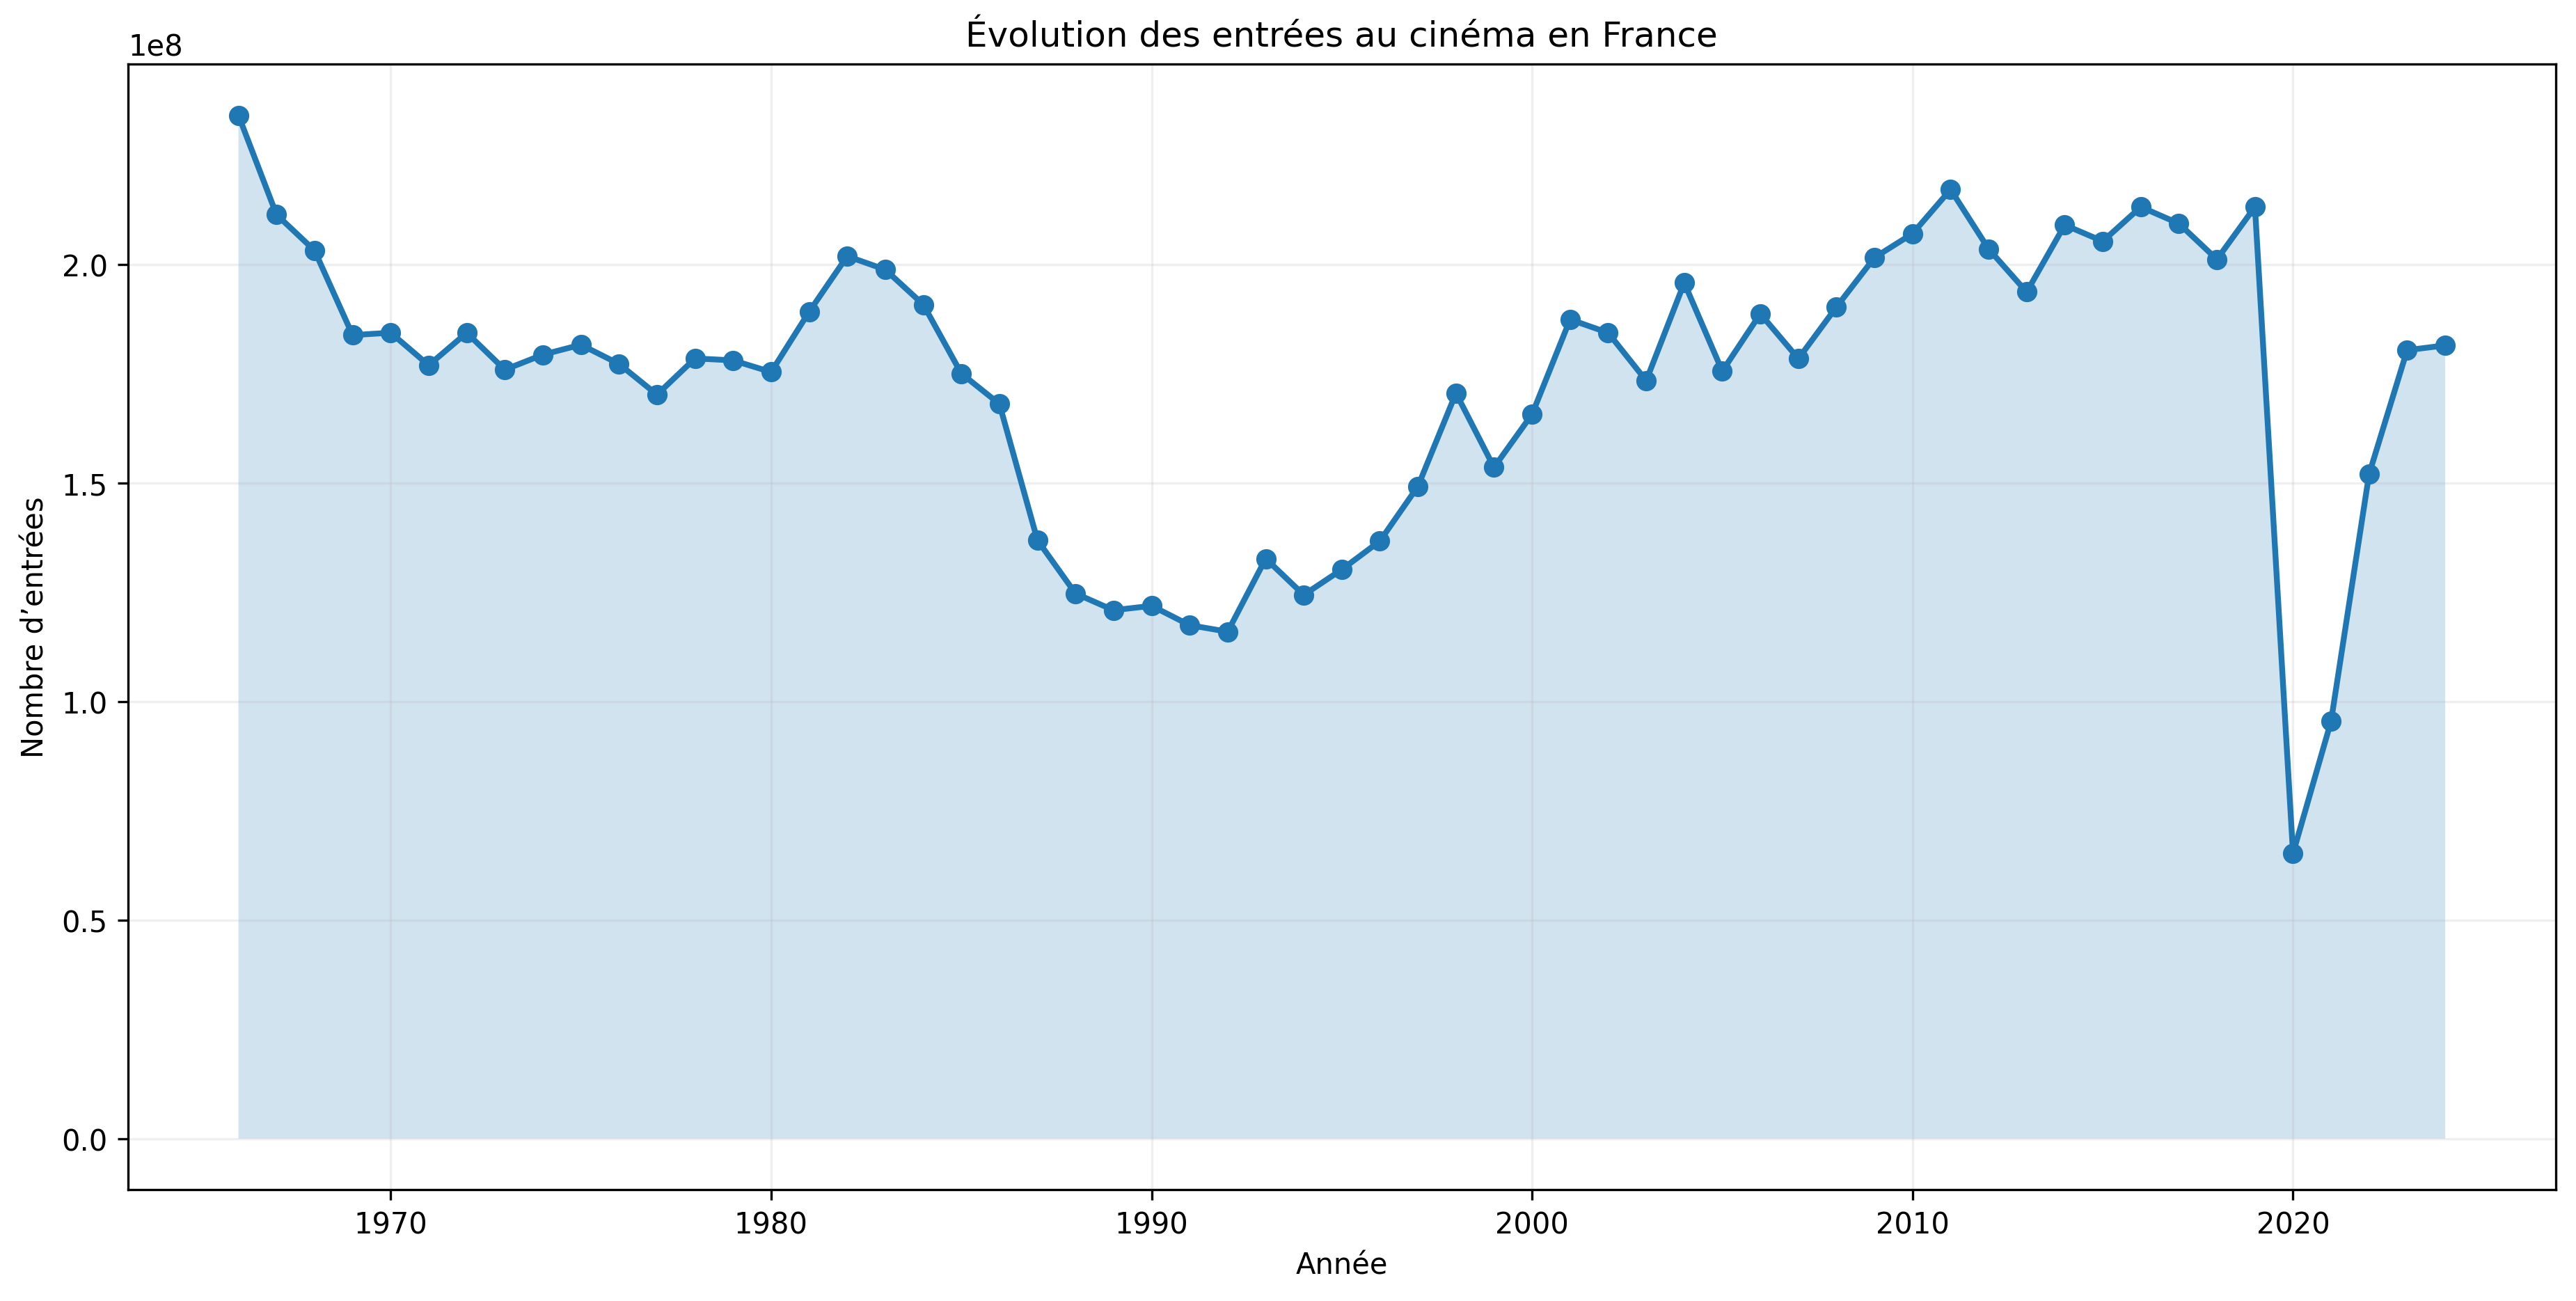

In [ ]:
import numpy as np

# Création de la figure et de l'axe
fig, ax = plt.subplots(figsize=(15, 7), dpi=300)

# Traçage de l’évolution temporelle du nombre d’entrées au cinéma
ax.plot(
    France_evolution["Year"].astype(int),
    France_evolution["Nombre_entrees"].astype(float),
    marker="o",
    linewidth=2
)
#Attention: .astype() est très important car Pandas stocke les colonnes
#avec un type objet et nous pour la visualisation nous avons besoin
#de bien définir le type

# Ajout d’une zone colorée sous la courbe
ax.fill_between(
    France_evolution["Year"].astype(int),
    France_evolution["Nombre_entrees"].astype(float),
    alpha=0.2
)

# Paramétrage des axes et du titre
ax.set_title("Évolution des entrées au cinéma en France")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre d’entrées")
ax.grid(True, alpha=0.2)

plt.show()


## Un focus sur la régions Auvergnes-Rhone-Alpes

In [ ]:
#Selection de la region rhone-alpes
# Sélection de la ligne correspondant à la région Auvergne-Rhone-Alpes

rhone_evolution = data_2.iloc[[0]].copy()

#On transpose pour avoir les années en lignes
rhone_evolution = rhone_evolution.T

# Changement d'intitulé pour les colonnes
rhone_evolution.index.name = "Year"
rhone_evolution = rhone_evolution.rename(columns={6: "Nombre_entrees"})

#Suppression de la ligne descriptive "Region", devenue inutile après la transposition
rhone_evolution = rhone_evolution.drop(index=["Region"])

#Réinitialisation de l'index pour transformer "Year" en colonne
rhone_evolution = rhone_evolution.reset_index()



In [ ]:
import matplotlib.colors as mcolors
# Sélection de la palette de couleurs "coolwarm" de Matplotlib
cmap = plt.cm.coolwarm
#Détérminer les bords de notre colonnes pour choisir le bon spectre de couleur
vmin = rhone_evolution["Nombre_entrees"].min()
vmax = rhone_evolution["Nombre_entrees"].max()
#Associer chaques valeurs à chaques couleurs
norm = mcolors.Normalize(
    vmin=vmin,
    vmax=vmax
)
rhone_evolution

,Year,Nombre_entrees
0,1966.0,21911664.0
1,1967.0,20066356.0
2,1968.0,19271896.0
3,1969.0,17968172.0
4,1970.0,18166206.0
5,1971.0,17492467.0
6,1972.0,18196735.0
7,1973.0,17775071.0
8,1974.0,18358414.0
9,1975.0,18390913.0


### Visualisation et interpretations des données (Rhone-Alpes)
---

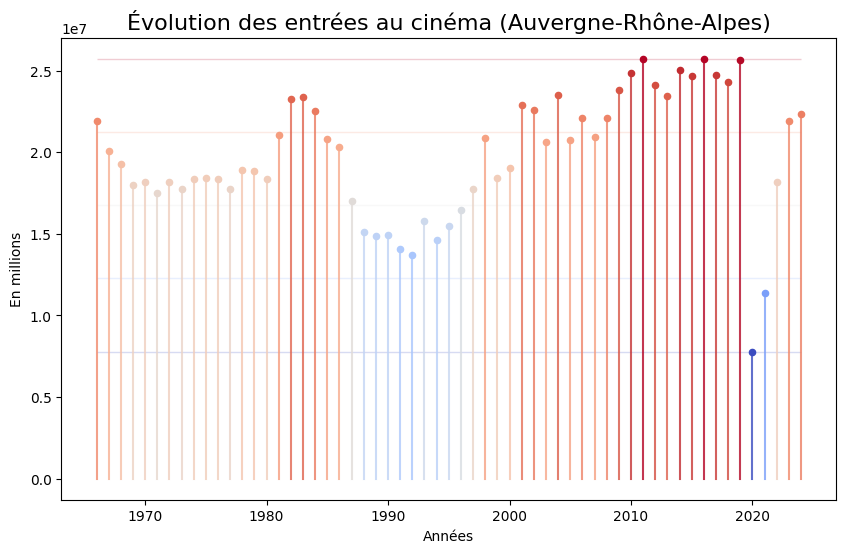

In [ ]:
import numpy as np
# Création de la figure et de l'axe
fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

# Traçage de l’évolution temporelle du nombre d’entrées au cinéma
for _, row in rhone_evolution.iterrows():
    year = int(row["Year"])
    change = int(row["Nombre_entrees"])
    color = cmap(norm(change))

    ax.scatter(x=year, y=change, color=color, s=20)
    ax.plot([year, year], [0, change], color=color, alpha=0.8)


# Lignes horizontales de référence
h_lines = np.linspace(
    rhone_evolution["Nombre_entrees"].min(), rhone_evolution["Nombre_entrees"].max(), 5
)

## Ces lignes servent de repères visuels pour situer les niveaux
ax.hlines(
    y=h_lines,
    xmin=rhone_evolution["Year"].min(),
    xmax=rhone_evolution["Year"].max(),
    colors=[cmap(norm(val)) for val in h_lines],
    linewidth=1,
    alpha=0.2,
    zorder=-1
)

plt.title("Évolution des entrées au cinéma (Auvergne-Rhône-Alpes)", fontsize=16)
plt.ylabel("En millions")
plt.xlabel("Années")
plt.show()

#### Interprétation des résultats
- On observe des oscillations dans le nombre d'entrées au cinéma en région Rhône-Alpes. La période 2010-2019 se distingue par un niveau particulièrement élevé, dépassant 2,5 millions d'entrées. En 2020, la courbe subit ensuite une chute brutale (moins de 0,7 million), principalement liée aux confinements et aux restrictions sanitaires dues au Covid-19.

- Ce qui retient surtout l'attention, c'est la dynamique de reprise : depuis la pandémie, la fréquentation remonte fortement, avec une trajectoire qui suggère une accélération nette. La question est donc la suivante : assiste-t-on à une véritable relance durable du secteur dans la région ? Cette tendance semble d'ailleurs dépasser l'échelle régionale et s'inscrire dans un mouvement plus large, à l'échelle nationale.

- Cependant, plusieurs obstacles peuvent freiner cette reprise. Le plus visible est la concurrence des plateformes de streaming, mais elle n'est pas la seule. D'autres facteurs, que nous analyserons dans la suite du notebook, permettent de mieux comprendre les limites et les conditions de cette relance.

In [ ]:
import pandas as pd
import folium
import pandas as pd
import json
from urllib.request import urlopen
 #Permet d'ouvrir un url comme çi c'est un fichier

#Problème :Le fichier et de type json, alors on va suivre des étapes d'informations retrouver sur internet
url = "https://www.data.gouv.fr/api/1/datasets/r/0f7f3c71-44f5-4084-b2da-275d2fe77561"

geo = json.load(urlopen(url))  # charge le GeoJSON (dict), clé,valeurs,utilité
# print(geo.keys())# Les features (variables disponibles)

features = geo["features"]             # liste des features

# 1-Regrouper les properties en colonnes
props = pd.json_normalize([f["properties"] for f in features])
# print(props)

# 2-extraire coordonnées  (GeoJSON =[lon, lat])
coords = pd.DataFrame([f["geometry"]["coordinates"] for f in features], columns=["lon","lat"])

# 3-Resulat
df_cinema_Lyon = pd.concat([props, coords], axis=1)

# *******************************************

df_cinema_Lyon.head()

print(df_cinema_Lyon.columns)

# Création d’une carte interactive centrée sur la ville de Lyon
m = folium.Map(location=[45.764, 4.835], zoom_start=12)

# Parcours des cinémas disposant de coordonnées géographiques valides
for _, r in df_cinema_Lyon.dropna(subset=["lat","lon"]).iterrows():
  # Ajout d’un marqueur circulaire pour chaque cinéma
    # positionné à partir de sa latitude et de sa longitude
    folium.CircleMarker(
        location=[r["lat"], r["lon"]],
        radius=5,
        popup=str(r.get("nom","cinema3d")),# Nom du cinéma affiché au clic
        fill=True
    ).add_to(m)

m


Index(['nom', 'commune', 'insee', 'adresse', 'capacite', 'nbecrans',
       'cinema3d', 'source', 'gid', 'address.postalCode',
       'address.streetAddress', 'address.addressCountry',
       'address.addressLocality', 'url', 'horaires', 'telephone',
       'openinghours', 'lon', 'lat'],
      dtype='object')


L'objectif de cette visualisation est de mettre en évidence le fort déséquilibre dans la répartition des cinémas à Lyon : la majorité d'entre eux se concentre dans le nord de la ville. Cette observation soulève alors une question centrale : pourquoi le nord précisément ? Pour y répondre, nous avons orienté l'analyse vers les caractéristiques socio-économiques des habitants, en particulier le taux de pauvreté par departement peut expliquer ou pas la fréquentation des cinémas.

##Dataset sur les informations par départements

### Ajouts des différents datasets et nettoyage du dataset final

In [ ]:
import pandas as pd
import numpy as np
#Importation des données
epci = pd.read_excel("sample_data/epcisanscom2021.xlsx")
pauvre = pd.read_excel("sample_data/Figure2b.xlsx")
repart = pd.read_excel("sample_data/TCRD_021.xlsx")

#nettoyage des données
pauvre.rename(columns ={pauvre.columns[0]: "Code",
                        pauvre.columns[1]: "Nom",
                        pauvre.columns[2]: "Taux"}, inplace =True)
pauvre.dropna(inplace = True)

repart.rename(columns ={repart.columns[0]: "dep",
                        repart.columns[1]: "Nom",
                        repart.columns[2]: "Population",
                        repart.columns[3]: "part de femmes",
                        repart.columns[4]: "part d hommes",
                        repart.columns[5]: "part des 0 à 24 ans",
                        repart.columns[6]: "part des 25 à 59 ans",
                        repart.columns[7]: "part des plus de 60 ans",
                        repart.columns[8]: "part des plus de 75 ans"}, inplace =True)
repart.dropna(inplace = True)

#On enlève les données nationales
repart.drop( repart[ repart['dep'] == 'F' ].index, inplace=True)
repart

epci.rename(columns={epci.columns[0]:"dep",
                     epci.columns[1]:"code",
                     epci.columns[2]:"nom",
                     epci.columns[3]:"1",
                     epci.columns[4]:"2",
                     epci.columns[5]:"3",
                     epci.columns[6]:"4",
                     epci.columns[7]:"5",}, inplace = True)

#On enlève les données qui ne sont pas sur tous les tableaux
epci.drop( epci[(epci['dep']== 671) |
                (epci['dep']== 673) |
                (epci['dep']== 676)].index, inplace = True)

#On enlève les colonnes inutiles
epci.drop(columns ='1', inplace = True)
epci.drop(columns ='2', inplace = True)
epci.drop(columns ='3', inplace = True)
epci.drop(columns ='4', inplace = True)
epci.drop(columns ='5', inplace = True)
epci.sort_values(by='code', inplace = True)

#On fusionne le tableau de tous les epci et celui avec
#le taux de pauvreté par ecpi.
pauvre = pd.merge(pauvre,
                  epci,
                  left_on='Code',
                  right_on ='code',
                  how = 'left')
pauvre.drop(columns = 'code',inplace = True)
pauvre.drop(columns = 'nom', inplace = True)
pauvre.drop(columns = 'Nom',inplace = True)
pauvre.drop(columns = 'Code',inplace = True)

#On fait regroupe les epci par département et on calcule la
#moyenne de leur taux de pauvreté.
dep = pauvre.groupby(by=['dep'])
result = dep.mean()

#On fusionne le nouveau tableau avec celui de la répartition par département.
repart = pd.merge(repart,
                  result,
                  left_on='dep',
                  right_on ='dep',
                  how = 'right')

data_4=pd.read_excel("https://www.data.gouv.fr/api/1/datasets/r/48da6e72-99c5-439f-865b-581a37102e4b",sheet_name="entrées")
data_4.rename(columns={data_4.columns[0]:"dep",
                     data_4.columns[60]:"donnee"}, inplace = True)

data_4.dropna(how='any', inplace= True)
dep=pd.DataFrame(data ={'dep': data_4['dep'], 'donnee':data_4['donnee']})

repart = pd.merge(repart,
                  dep,
                  left_on='dep',
                  right_on ='dep',
                  how = 'inner')

repart = repart.set_index("dep")
repart.drop('Nom',axis = 1, inplace = True)
repart['donnee'] = repart['donnee']/repart['Population']
repart.rename(columns={repart.columns[7]:'Taux de pauvreté',
                       repart.columns[8]:'Rapport entrée/Population'}, inplace = True)
repart

,Population,part de femmes,part d hommes,part des 0 à 24 ans,part des 25 à 59 ans,part des plus de 60 ans,part des plus de 75 ans,Taux de pauvreté,Rapport entrée/Population
dep,,,,,,,,,
01,688626,50.7,49.3,29.7,44.8,25.5,9.3,9.835714,1.385113
02,518817,51.1,48.9,28.9,41.7,29.4,10.6,17.415789,1.510338
03,332599,51.7,48.3,24.4,39,36.6,14.9,16.072727,1.927147
04,169806,51.5,48.5,24.1,39.9,35.9,14.3,17.5625,2.599143
05,142006,51.1,48.9,23.1,41.1,35.8,14,14.5,3.173619
...,...,...,...,...,...,...,...,...,...
88,352304,51.1,48.9,25.2,40.6,34.2,12.9,15.38,2.161176
89,331131,51.1,48.9,26,40.7,33.3,12.8,14.228571,1.969583
90,138419,50.3,49.7,29.5,42.8,27.7,10.3,13.7,2.136824


### ACP et différentes visualisations de celle-ci

 Création de l'ACP

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

x = StandardScaler().fit_transform(repart)
compo = ['carac'+str(i) for i in range(x.shape[1])]
normal_x = pd.DataFrame(x,columns = compo)
pca_x = PCA(n_components=2)
PCA_X = pca_x.fit_transform(x)

X=pd.DataFrame(data = PCA_X, columns=['composante 1', 'composante 2'])
#print('Les composantes contiennent tant de % d information : {}'.format(pca_x.explained_variance_ratio_))
#52 % et 29%
X

,composante 1,composante 2
0,-2.064680,-2.584219
1,-0.095605,-0.849472
2,2.493684,1.219669
3,2.269465,1.072333
4,1.829536,0.175961
...,...,...
87,1.411876,-0.338371
88,1.139967,-0.596355
89,-0.632152,-2.969727
90,-3.808827,-2.214035


Visualisation de notre ACP en mettant le niveau de vie de chaque département en avant

<Figure size 640x480 with 0 Axes>

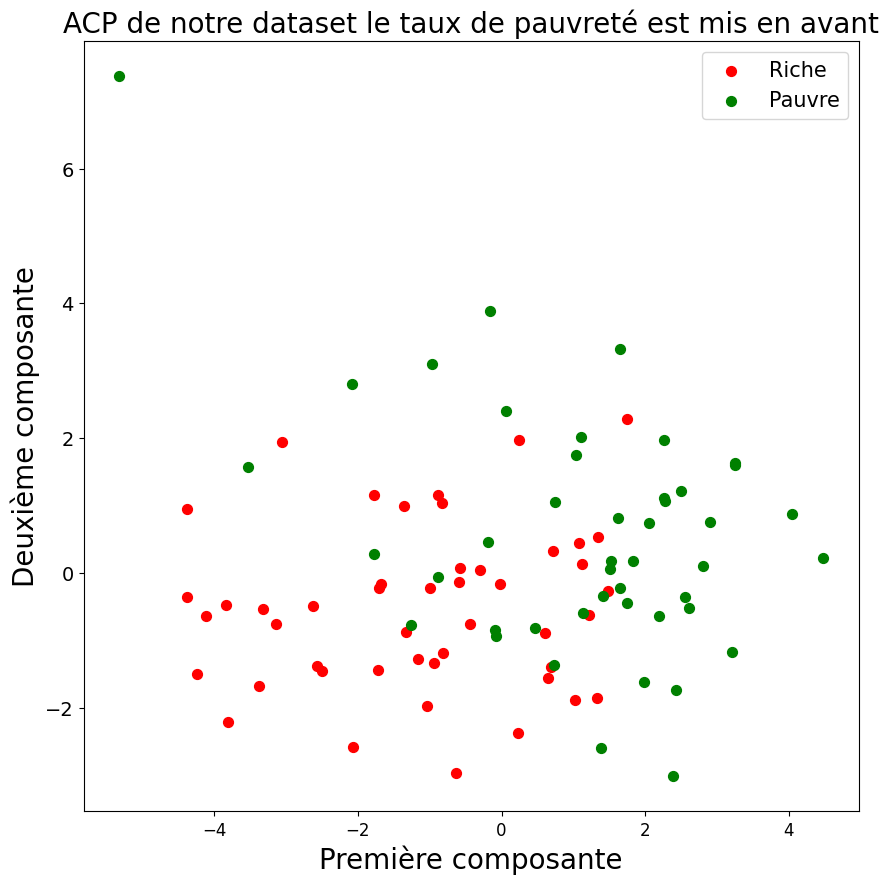

In [ ]:
mean = round(np.mean(repart['Taux de pauvreté']))
statut1=np.where(repart['Taux de pauvreté']>mean, 'Pauvre', 'Riche')
X['statut1']= statut1
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset le taux de pauvreté est mis en avant",fontsize=20)
targets = ['Riche', 'Pauvre']
colors = ['r', 'g']
for target, color in zip(targets,colors):
    indicesToKeep = X['statut1'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)

plt.legend(targets,prop={'size': 15})

On remarque que les départements les plus riches se situent majoritairement à gauche ou au centre du graphique et à l'inverse les plus pauvres sont plutôt à droite, on peut voir qu'au centre les points sont assez mélangés. Il semblerait que la première composante contiennent une partie de la variable du niveau de vie.

Visualisation de notre ACP en mettant la répartition hommes/femmes  de chaque département en avant

<Figure size 640x480 with 0 Axes>

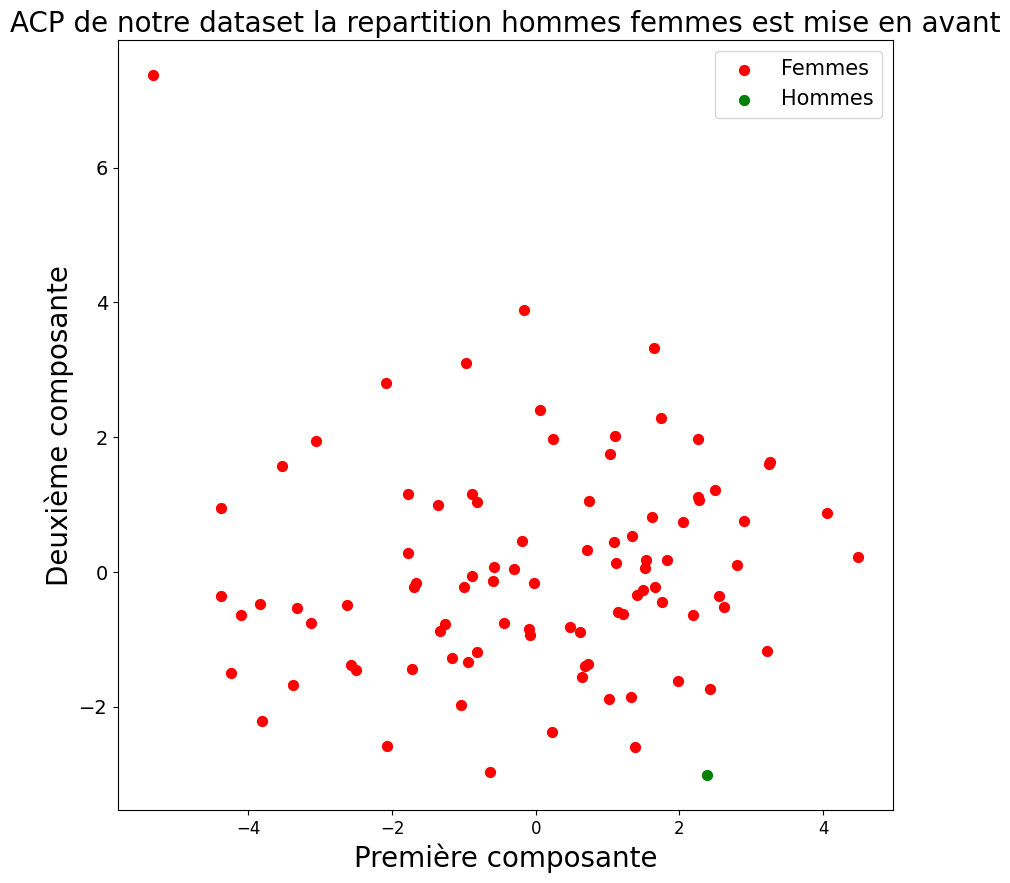

In [ ]:
statut2 = np.where(repart['part de femmes']>50, 'Femmes', 'Hommes')
X['Statut2']= statut2

plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset la repartition hommes femmes est mise en avant",fontsize=20)
targets = ['Femmes', 'Hommes']
colors = ['r', 'g']
for target, color in zip(targets,colors):
    indicesToKeep = X['Statut2'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)

plt.legend(targets,prop={'size': 15})

On voit qu'un seul point est vert sur sur l'ensemble des points. On explique cela par le fait que tous les départements sauf la Lozère ont une plus grande population féminine que masculine, la Lorère fait exception avec 50.1% de population masculine.
Étant donné que les points sont très mal répartis par rapport à cette variable, il est très difficile de déduire quelque chose de ce graphique.

Visualisation de notre ACP en mettant la population de chaque département en avant

<Figure size 640x480 with 0 Axes>

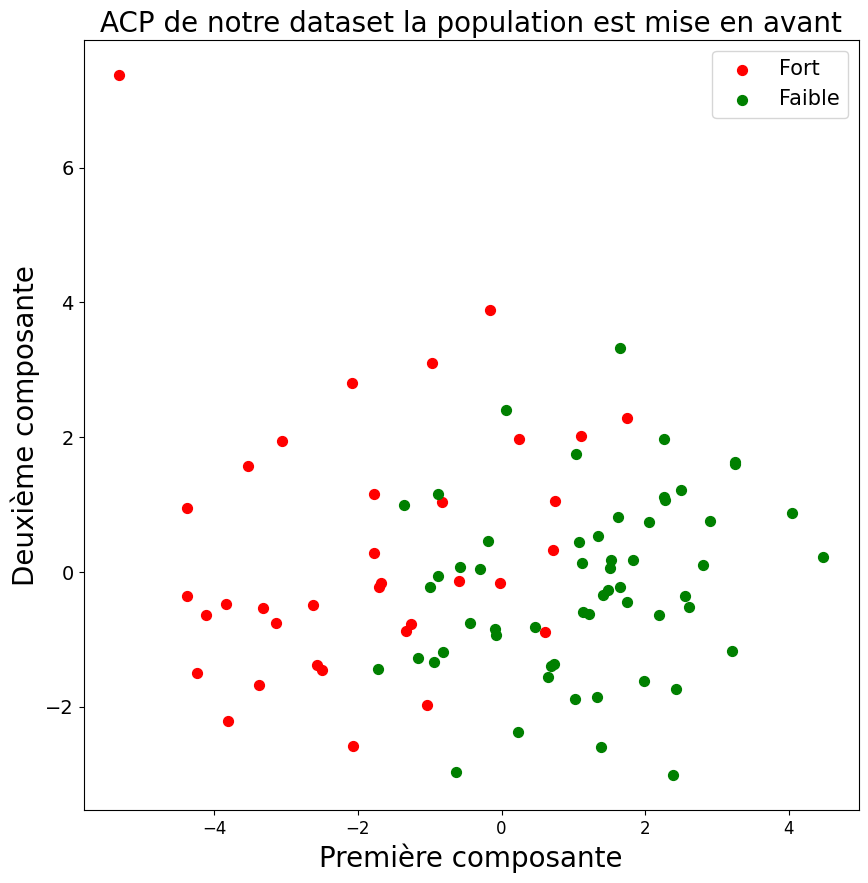

In [ ]:
moy_pop = np.mean(repart['Population'])
statut3 = np.where(repart['Population']>moy_pop, 'Fort', 'Faible')
X['Statut3']= statut3

plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset la population est mise en avant",fontsize=20)
targets = ['Fort', 'Faible']
colors = ['r', 'g']
for target, color in zip(targets,colors):
    indicesToKeep = X['Statut3'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)

plt.legend(targets,prop={'size': 15})

Fort : départements avec une population supérieure à la moyenne des départements français.

Fabile : départements avec une population inférieure à la moyenne des départements français.

Ce graphique nous permet d'observer une tendance : les départements les plus peuplés semblent être plus à gauche et les moins peuplés a droite, mais on peut voir qu'au milieu les points sont assez mélangés. On peut donc penser que la première composante contient une partie des informations de la variable de la population.

Visualisation de notre ACP en mettant le rapport entrée/population de chaque département en avant

<Figure size 640x480 with 0 Axes>

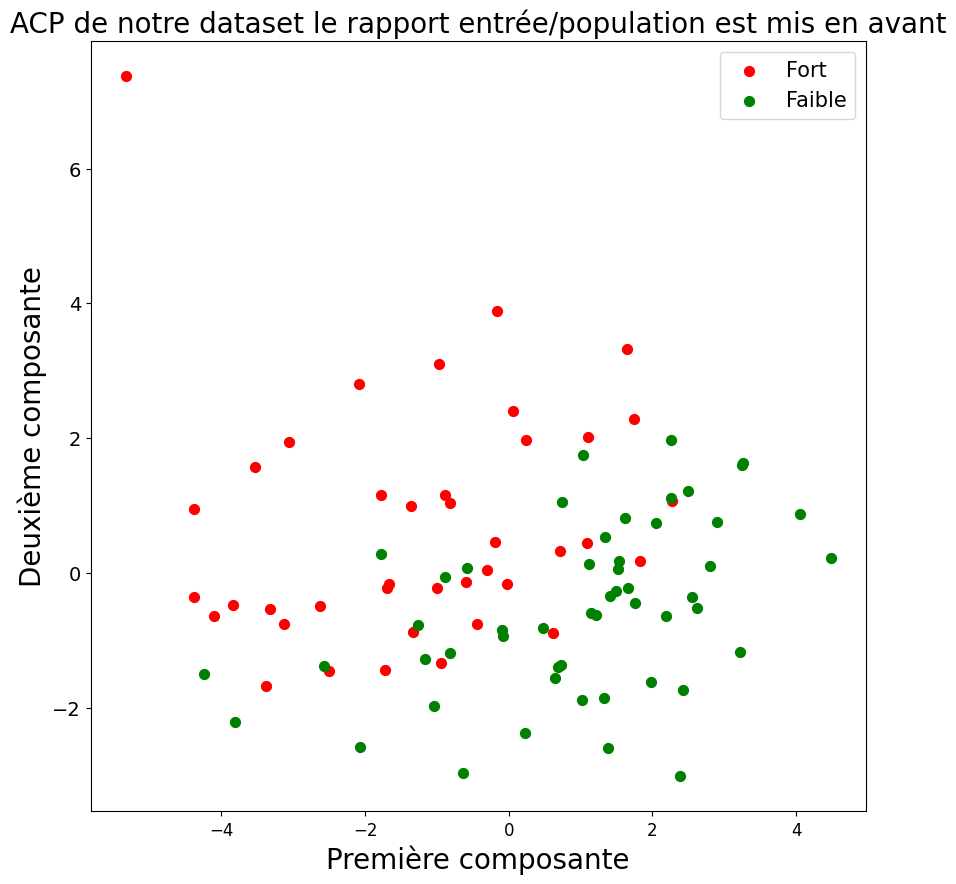

In [ ]:
moy_ciné = np.mean(repart['Rapport entrée/Population'])
statut4 = np.where(repart['Rapport entrée/Population']>moy_ciné, 'Fort', 'Faible')
X['Statut4']= statut4

plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset le rapport entrée/population est mis en avant",fontsize=20)
targets = ['Fort', 'Faible']
colors = ['r', 'g']
for target, color in zip(targets,colors):
    indicesToKeep = X['Statut4'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)

plt.legend(targets,prop={'size': 15})

Fort : départements avec un rapport entrée/population supérieur à la moyenne des départements français.

Faible : départements avec un rapport entrée/population inférieur à la moyenne des départements français.

Ce graphique est assez difficile à lire, on peut observer une tendance, mais c'est assez limité. On peut dire que les départements avec les rapports les plus faibles se situent en bas à droite du graphique et à l'inverse les départements avec un rapport important se situent plus à gauche et plus haut que les autres départements, mais au centre du graphique les points sont assez mélangés.
Il semblerait que les informations lié à la variable mise en avant est contenue dans les deux composantes.

#### Visualisation de notre ACP en mettant la répartition de 0-24 ans de chaque département en avant

<Figure size 640x480 with 0 Axes>

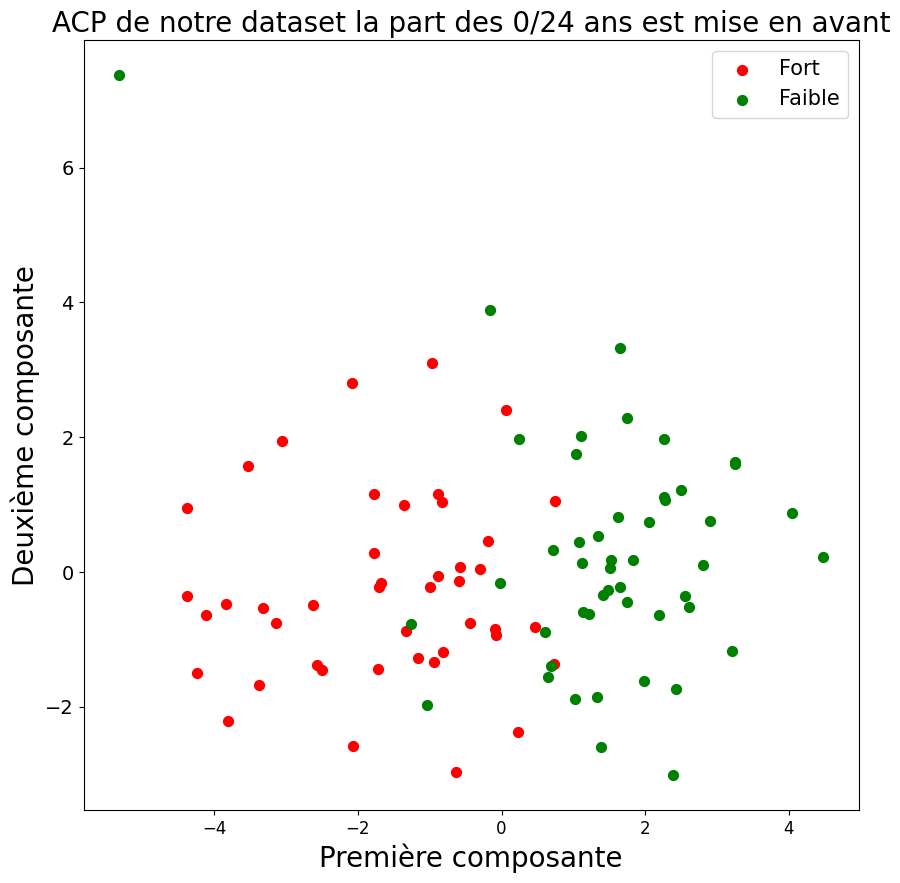

In [ ]:
moy_jeun = np.mean(repart['part des 0 à 24 ans'])
statut5 = np.where(repart['part des 0 à 24 ans']>moy_jeun, 'Fort', 'Faible')
X['Statut5']= statut5

plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset la part des 0/24 ans est mise en avant",fontsize=20)
targets = ['Fort', 'Faible']
colors = ['r', 'g']
for target, color in zip(targets,colors):
    indicesToKeep = X['Statut5'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)

plt.legend(targets,prop={'size': 15})

Fort : départements avec une proportion de 0-24 ans supérieure à la moyenne des département français.

Faible : départements avec une proportion de 0-24 ans inférieure à la moyenne des département français.

On peut voir que les départements avec une plus grande répartition de 0-24 ans se situent à gauche et à l'inverse les départements avec une plus petite répartition de 0-24 ans se situent à droite

Visualisation de notre ACP en mettant la répartition des plus de 60 ans de chaque département en avant.

<Figure size 640x480 with 0 Axes>

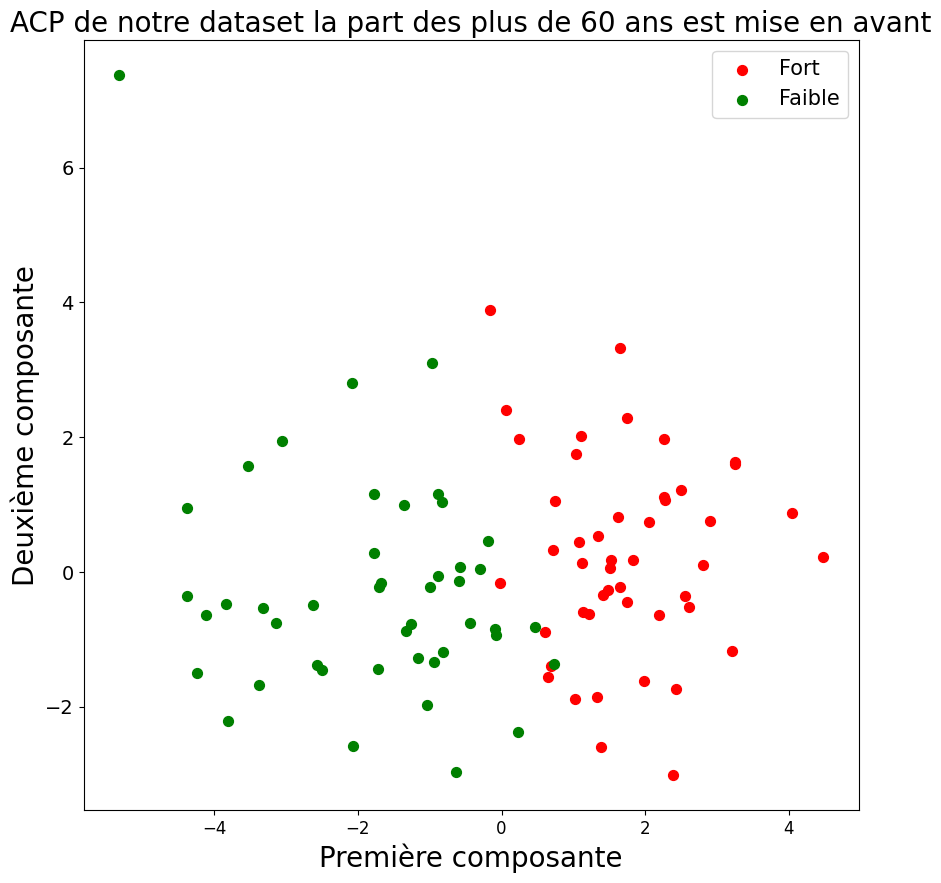

In [ ]:
moy_vieu = np.mean(repart['part des plus de 60 ans'])
statut6 = np.where(repart['part des plus de 60 ans']>moy_vieu, 'Fort', 'Faible')
X['Statut6']= statut6

plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset la part des plus de 60 ans est mise en avant",fontsize=20)
targets = ['Fort', 'Faible']
colors = ['r', 'g']
for target, color in zip(targets,colors):
    indicesToKeep = X['Statut6'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)

plt.legend(targets,prop={'size': 15})

Fort : départements avec une proportion de plus de 60 ans supérieure à la moyenne des département français.

Faible : départements avec une proportion de de plus de 60 ans inférieure à la moyenne des département français.

Avec cette visualisation, on peut dire que les département avec une grande répartition de plus de 60 ans se situent à droite et à l'inverse ceux avec une répartition plus faible des plus de 60 ans à gauche.

*Mise en évidence du département de Paris*

<Figure size 640x480 with 0 Axes>

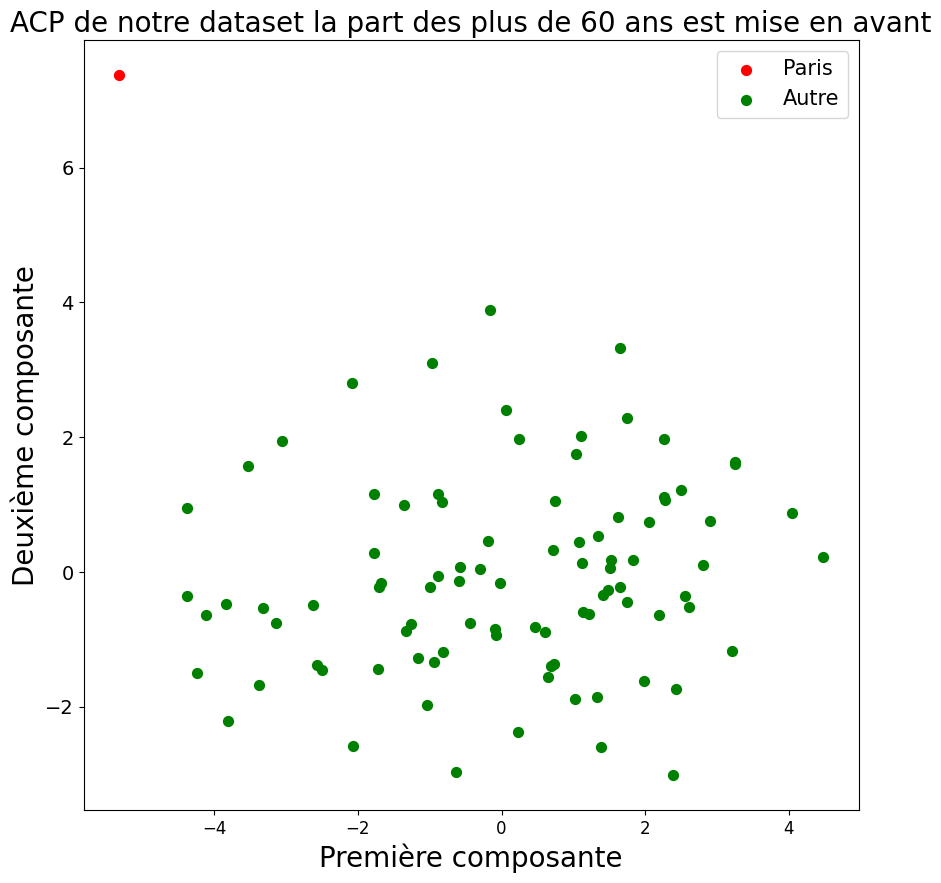

In [ ]:
statut7 = np.where(repart.index=='75', 'Paris', 'Autre')
X['Statut7']= statut7

plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset la part des plus de 60 ans est mise en avant",fontsize=20)
targets = ['Paris', 'Autre']
colors = ['r', 'g']
for target, color in zip(targets,colors):
    indicesToKeep = X['Statut7'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)

plt.legend(targets,prop={'size': 15})

On peut remarquer un point qui se sépare du nuage de point, il s'agit du département 75, le département de Paris. Ce département se démarque par sa population et son rapport entrées/population. En effet ce département a plus de 2 millions d'habitants et son rapport entrée/population est à plus de 8 alors que tous les autres départements ont un rapport autour de 1 à 3. Ce qui est assez logique, le cinéma le plus fréquenté du monde est à Paris il s'agit de UGC ciné cité les Halles, avec plus de 2.8 millions d'entrées annuelles.
Si ce département est aussi haut et à droite, on peut penser que plus un département est peuplé ou plus son rapport entrée/population est élevé, plus il est haut dans le graphique. Et on peut avoir le même raisonnement avec le fait que ce point soit autant à droite. Avec ce seul point, il est difficile de déduire quelque chose.

*Mise en commun des visualisation*

On peut conclure grâce à toutes ces visualisations que la première composante oppose très nettement les départements "vieux" et "jeunes", mais on remarque aussi que cette composante oppose aussi les départements "peuplés" et "moins peuplés" et les départements "riches" et "pauvres" mais de manière moins nette. Comme les départements avec un rapport entrées/population élevé se situent majoritairement à gauche, on peut supposer que les variables de la proportion de jeunes, et du niveaux de vie et du nombre d'habitants sont corrélés positivement avec celle du rapport entrée/population. Selon cette théorie les habitants des départements "jeunes", "peuplés" et "riches"vont plus au cinéma.

In [ ]:
matrice_cov =normal_x.cov()
normal_x.rename(columns ={normal_x.columns[0]: "Population",
                        normal_x.columns[1]: "Part de femmes",
                        normal_x.columns[2]: "Part d'hommes",
                        normal_x.columns[3]: "part de jeunes",
                        normal_x.columns[4]: "part de 25-59 ans",
                        normal_x.columns[5]: "part des plus de 60 ans",
                        normal_x.columns[6]: "part des plus de 70 ans",
                        normal_x.columns[7]: "niveau de pauvreté",
                        normal_x.columns[8]: "rapport entrées/population"}, inplace =True)
matrice_cov =normal_x.cov()
matrice_cov.style.background_gradient(cmap='coolwarm').format(precision=5)

,Population,Part de femmes,Part d'hommes,part de jeunes,part de 25-59 ans,part des plus de 60 ans,part des plus de 70 ans,niveau de pauvreté,rapport entrées/population
Population,1.01099,0.40388,-0.40388,0.60529,0.72280,-0.71218,-0.65901,-0.25588,0.53417
Part de femmes,0.40388,1.01099,-1.01099,-0.06365,0.07957,-0.00106,0.10061,0.28595,0.49797
Part d'hommes,-0.40388,-1.01099,1.01099,0.06365,-0.07957,0.00106,-0.10061,-0.28595,-0.49797
part de jeunes,0.60529,-0.06365,0.06365,1.01099,0.71127,-0.94845,-0.93377,-0.51498,0.12596
part de 25-59 ans,0.72280,0.07957,-0.07957,0.71127,1.01099,-0.91598,-0.88944,-0.41293,0.52986
part des plus de 60 ans,-0.71218,-0.00106,0.00106,-0.94845,-0.91598,1.01099,0.98919,0.50759,-0.33327
part des plus de 70 ans,-0.65901,0.10061,-0.10061,-0.93377,-0.88944,0.98919,1.01099,0.49678,-0.23957
niveau de pauvreté,-0.25588,0.28595,-0.28595,-0.51498,-0.41293,0.50759,0.49678,1.01099,-0.13877
rapport entrées/population,0.53417,0.49797,-0.49797,0.12596,0.52986,-0.33327,-0.23957,-0.13877,1.01099


La matrice de covariance nous permet de valider certaines de nos hypothèses. On retrouve l'idée que la corrélation entre le rapport entrées/population et la population est positif, même constat avec la part de jeune dans le département. Pour le niveau de pauvreté, la corrélation est négative mais c'est logique car plus cette variable est élevée plus le département est pauvre.

Finalement, on se rend compte que, selon notre dataset, la principale variable qui joue sur le rapport entrées/population par département est le nombre de personnes du département.

### Création de l'ACP

In [ ]:
data_acp = data_1.drop('rang',axis=1)
data_acp.drop('titre',axis=1,inplace = True)
data_acp.drop('réalisateur',axis=1,inplace = True)
data_acp.drop('nationalité1',axis=1,inplace = True)
data_acp.drop('genre',axis=1,inplace = True)
data_acp.drop('genre_num',axis=1,inplace = True)
data_acp.drop('nationalité_num',axis=1,inplace = True)

data_acp['Durée (en min)'] = pd.to_numeric(data_acp['Durée (en min)'])
data_acp['Note'] = pd.to_numeric(data_acp['Note'])

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

x = StandardScaler().fit_transform(data_acp)
compo = ['carac'+str(i) for i in range(x.shape[1])]
normal_x = pd.DataFrame(x,columns = compo)
pca_x = PCA(n_components=2)
PCA_X = pca_x.fit_transform(x)

X=pd.DataFrame(data = PCA_X, columns=['composante 1', 'composante 2'])
#print('Les composantes contiennent tant de % d information : {}'.format(pca_x.explained_variance_ratio_))
#Les composantes contiennent 34.87% et 26.95% d'informations.
data_acp


NameError: name 'data_1' is not defined

Nous avons enlevé les colonnes non numériques et avons également passé les éléments des colonnes de notes et du genre en entier, afin de faire notre ACP dans de bonnes conditions

Visualisation de notre ACP en mettant en avant les nationalités des films

NameError: name 'data_1' is not defined

<Figure size 640x480 with 0 Axes>

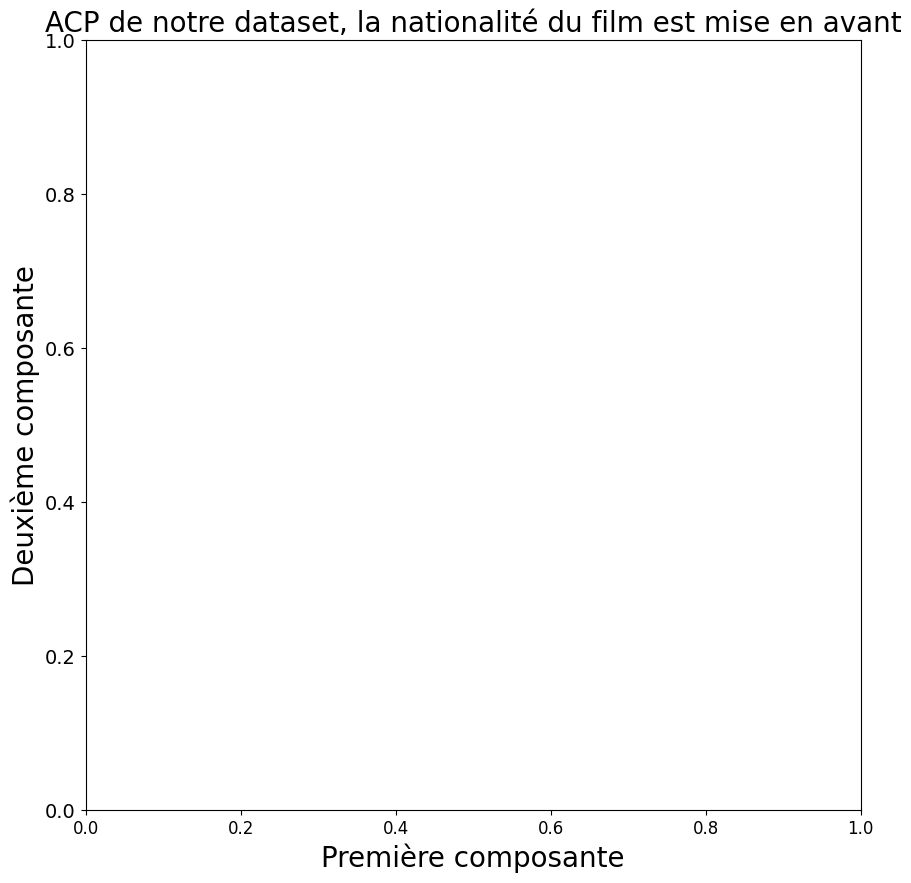

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.clf()
plt.close('all')
plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset, la nationalité du film est mise en avant",fontsize=20)
targets = [0,1, 2,3,4,5,6,7,8,9,10,11,12,13,14,15,16]
colors = ['red','green','green','yellow','blue','green','green','green','green','green','green','cyan','green','green','deeppink','black','orange']
for target, color in zip(targets,colors):
    indicesToKeep = data_1['nationalité_num'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)

plt.legend(['US','FR','FR/GB','IT','GB','IT/FR','FR/DE/IT','FR/DE','FR/CH','FR/BE','FR/ES','NZ','FR/MX','FR/DE/ES/IT','AT','ZA','AU'],prop={'size': 15})


Nous avons choisis de simplifier le graphique en ne différenciant pas les films uniquement français et les films français avec plusieurs nationalités.
Il est plutôt difficile de déduire des tendances de ce graphique, mais on peut tout de même voir que dans ces 200 films les plus vus au cinéma en France, la majorité d'entre eux sont américains ou français.

Visualisation de notre ACP en mettant en avant le genre des films

<Figure size 640x480 with 0 Axes>

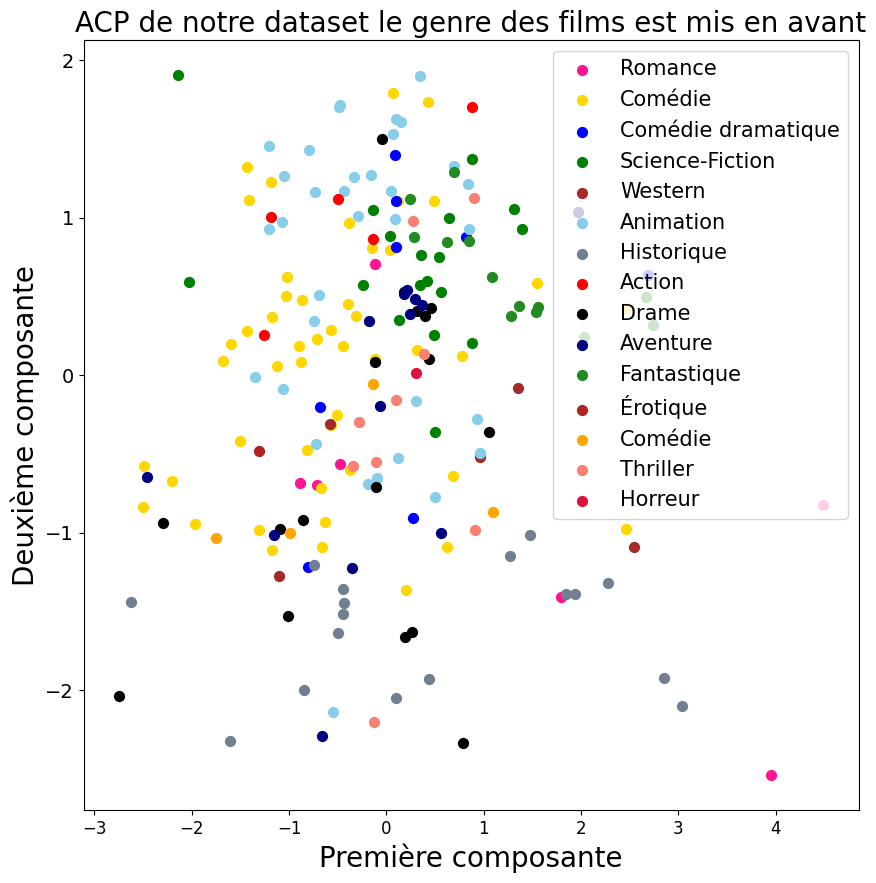

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.clf()
plt.close('all')
plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset le genre des films est mis en avant",fontsize=20)
targets = [0,1, 2,3,4,5,6,7,8,9,10,11,12,13,14]
colors = ['deeppink','gold','blue','green','brown','skyblue','slategray','red','black','navy','forestgreen','firebrick','orange','salmon','crimson']
for target, color in zip(targets,colors):
    indicesToKeep = data_1['genre_num'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)

plt.legend(['Romance','Comédie','Comédie dramatique','Science-Fiction','Western','Animation','Historique','Action','Drame','Aventure','Fantastique','Érotique','Comédie','Thriller','Horreur'],prop={'size': 15})

Ce graphique est assez complexe mais on peut tout de même retrouvé certaines tendances, par exemple les films de sciences fictions se retrouvent majoritairement en haut à droite dans le graphique. Les films historiques sont plutôt dans la partie inférieur du graphique. Les comédies se concentrent dans la partie droite du graphique. On peut expliquer la complexité de ce graphique par le fait que nous limité un seul genre par film, or il est rare que nous qualifions un film avec un seul genre.

Visualisation de notre ACP en mettant en avant la date de sortie des films

In [ ]:
mean_date =round(np.mean(data_acp['année de sortie']))
statut_date=np.where(data_acp['année de sortie']>mean_date, 'après 1982', 'avant 1982')
data_acp['statut_date']=statut_date

plt.clf()
plt.close('all')
plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset, la date de sortie du film est mise en avant",fontsize=20)
targets = ['avant 1982', 'après 1982']
colors = ['red','green']
for target, color in zip(targets,colors):
    indicesToKeep = data_acp['statut_date'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)
plt.legend(targets,prop={'size': 15})

NameError: name 'data_acp' is not defined

On remarque très clairement que les films sortis avant 1982 sont en bas du graphique et à l'inverse les films plus récents sont en haut du graphique.
Nous avons choisis de prendre 1982 comme répère car la moyenne de toutes les années de sortie nous donne 1982. Il semblerait que la deuxième composante contienne une grande partie des informations de la variable sur l'année de sortie du film.

Visualisation de notre ACP en mettant en avant la note du film

<Figure size 640x480 with 0 Axes>

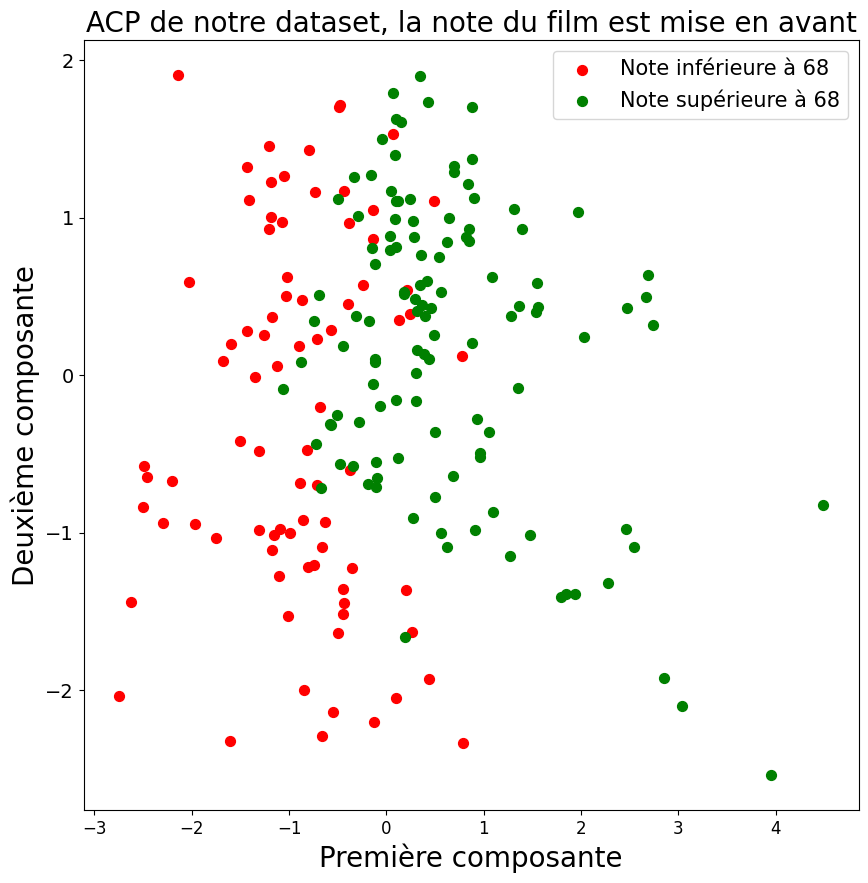

In [ ]:
mean_note =round(np.mean(data_acp['Note']))
statut_note=np.where(data_acp['Note']<mean_note, 'Note inférieure à 68', 'Note supérieure à 68')
data_acp['statut_note']=statut_note

plt.clf()
plt.close('all')
plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset, la note du film est mise en avant",fontsize=20)
targets = ['Note inférieure à 68', 'Note supérieure à 68']
colors = ['red','green']
for target, color in zip(targets,colors):
    indicesToKeep = data_acp['statut_note'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)
plt.legend(targets,prop={'size': 15})

Avec cette visualisation on arrive à voir que les films avec une note inférieure à 68 sont majoritairement à gauche dans le graphique et à l'inverse les films les mieux notés sont à droite. On peut supposer que la première composante contient une grande partie des informations de la variable de la note du film. Nous avons choisis 68 pour comparer les films car c'est la note moyenne des ces 200 films.

Visualisation de notre ACP en mettant en avant la durée du film

<Figure size 640x480 with 0 Axes>

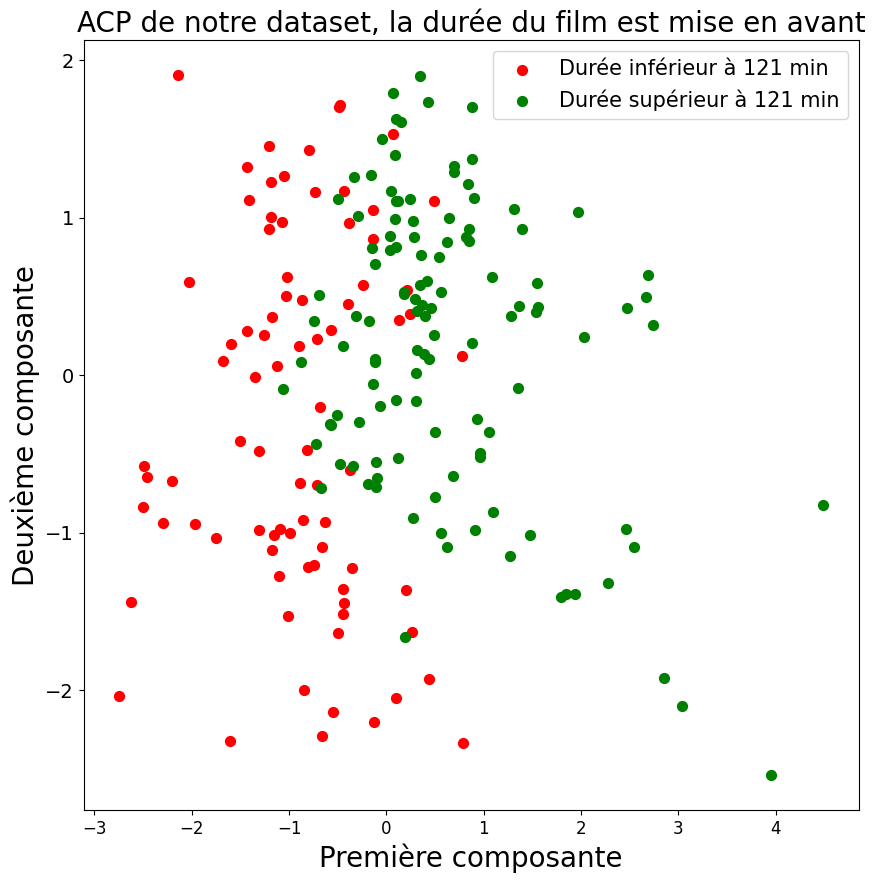

In [ ]:
mean_durée =round(np.mean(data_acp['Durée (en min)']))
statut_durée=np.where(data_acp['Note']<mean_note, 'Durée inférieur à 121 min', 'Durée supérieur à 121 min')
data_acp['statut_durée']=statut_durée

plt.clf()
plt.close('all')
plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset, la durée du film est mise en avant",fontsize=20)
targets = ['Durée inférieur à 121 min', 'Durée supérieur à 121 min']
colors = ['red','green']
for target, color in zip(targets,colors):
    indicesToKeep = data_acp['statut_durée'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)
plt.legend(targets,prop={'size': 15})

Ici aussi on arrive à observer une tendance, les films qui ont une durée inférieure à 121 min sont majoritairement à gauche dans le graphique et à l'inverse les films plus long sont majoritairement à droite. On peut donc dire que la première composante contient également une grande partie des informations de la variable sur la durée du film. La valeur 121 a été prise car c'est la durée moyenne de ces 200 films.

Visualisation de notre ACP en mettant en avant le nombre d'entrée pour chaque film

<Figure size 640x480 with 0 Axes>

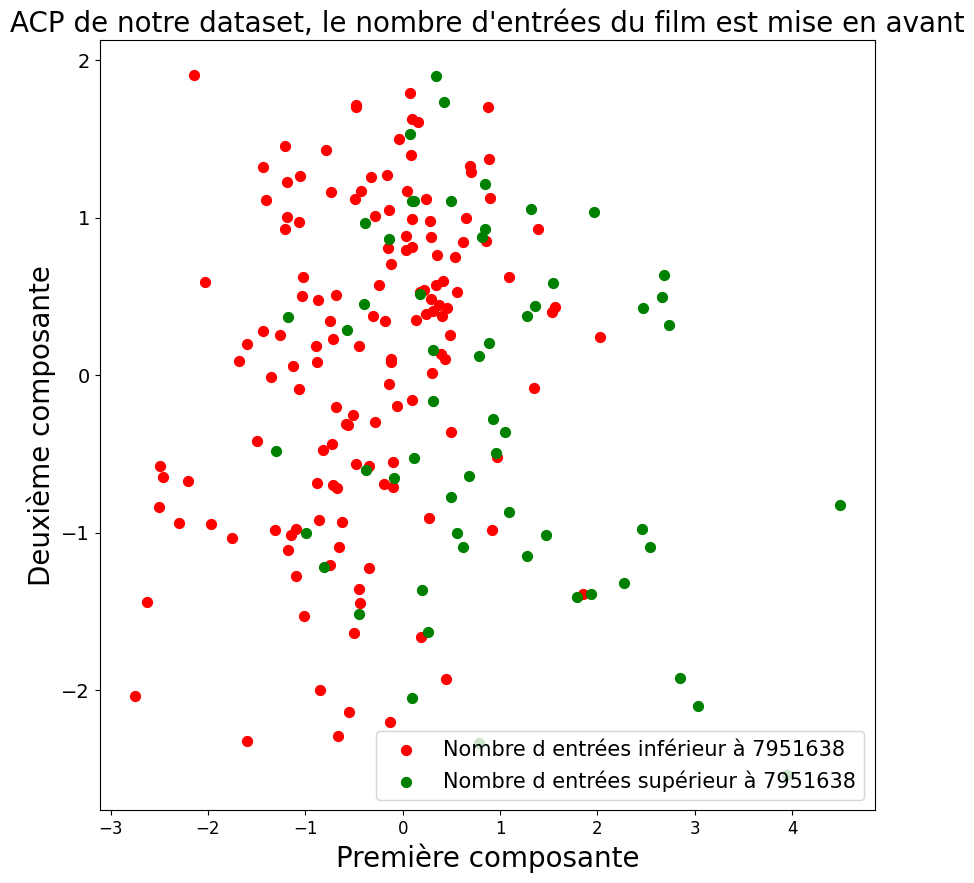

In [ ]:
mean_entrées =round(np.mean(data_acp['entrées (millions)2']))
statut_entrées=np.where(data_acp['entrées (millions)2']<mean_entrées, 'Nombre d entrées inférieur à 7951638', 'Nombre d entrées supérieur à 7951638')
data_acp['statut_entrées']=statut_entrées

plt.clf()
plt.close('all')
plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Première composante',fontsize=20)
plt.ylabel('Deuxième composante',fontsize=20)
plt.title("ACP de notre dataset, le nombre d'entrées du film est mise en avant",fontsize=20)
targets = ['Nombre d entrées inférieur à 7951638', 'Nombre d entrées supérieur à 7951638']
colors = ['red','green']
for target, color in zip(targets,colors):
    indicesToKeep = data_acp['statut_entrées'] == target
    plt.scatter(X.loc[indicesToKeep, 'composante 1']
               , X.loc[indicesToKeep, 'composante 2'], c = color, s = 50)
plt.legend(targets,prop={'size': 15})

On peut voir que ce graphique est plus difficile à lire que les précédents, les points sont un peu plus mélangés. Mais nous pouvons tout de même décrire une tendance, les films les plus vus se concentre à droite dans le graphique mais dans toute la longueur du graphique. Alors il semblerais que la première composante contient aussi des informations sur la variable du nombre d'entrées de chaque film.

- Du point de vue de la première composante:
Nous avons donc vu que les films avec un grand nombre d'entrées se regrouvent en majorité à droite dans le graphique. Mais les films bien notés ou long se retrouve aussi dans cette partie du graphique, alors on peut interpréter ce résultat en disant que la durée du film et la note du film ont une corrélation positive avec le nombre d'entrée du film. Autrement dit, les films qui ont eu un gros succès au cinéma sont en majorité des "grands films", des films longs et de bonnes qualité.

- Du point de vue de la deuxième composante :
Nous avons vu que les films avec un grand nombre d'entrées se regroupent dans toute la longueur du graphique à droite. Nous avons également remarqué que l'axe verticale contient en majorités les informations sur l'année de sortie du film. Comme le nombre d'entrées ne dépend pas de cette deuxième composante, on peut dire que la corrélation entre le nombre d'entrée du film et son année de sortie est proche de 0. Un film des années 60 peut avoir autant de succès qu'un film sortie en 2025.

Grâce a ces dernières visualisations, on comprend mieux les tendances obersvées dans le graphique sur les genres, les films de sciences-fictions sont plutôt récents et sont souvent de grands films. Les films historiques sont plus anciens il est donc logique qu'ils soient majoritairement dans la partie inférieure du graphique. Et pour finir les comédies se retrouvent dans toute la longueure de la partie droite car les comédies sont moins considérés comme des grands films, et que les comédies n'ont pas d'époque en 1960 comme en 2015 on peut aller voir des comédies au cinéma.

In [ ]:
normal_x.rename(columns ={normal_x.columns[0]: "année de sortie",
                        normal_x.columns[1]: "Nombre d'entrées",
                        normal_x.columns[2]: "Note",
                        normal_x.columns[3]: "Durée"}, inplace =True)
matrice_cov.style.background_gradient(cmap='coolwarm').format(precision=5)

,année de sortie,Nombre d'entrées,Note,Durée
année de sortie,1.00503,0.00066,0.15047,-0.06511
Nombre d'entrées,0.00066,1.00503,0.21027,0.18154
Note,0.15047,0.21027,1.00503,0.19110
Durée,-0.06511,0.18154,0.19110,1.00503


Grâce à cette matrice de covariance, nous pouvons confirmer nos hypothèses, les variables de la note et de la durée ont toutes les deux une covariance positive avec la variable du nombre d'entrées. De plus on voit aussi que la varaible de l'année de sortie a une covariance proche de 0 avec la variable du nombre d'entrées.
On arrive donc bien à la conclusion que la durée du film et sa note sont assez corrélées avec le nombre d'entrées au cinéma de ce film.

L'analyse de nos différents datasets nous ont permis de constater plusieurs choses :
- Des facteurs comme la richesse et la jeunnesse ont un effet positif sur le nombre de films vu par personne moyen par département. De plus nous avons remarqués que plus la démographie du département a aussi un effet positif sur cette même valeur. Mais il faut prendre certains rapport avec attention, certains départements comme Paris peuvent avoir des rapports entrées/population très élevé mais pour autant les Parisiens ne vont pas plus au cinéma que les provinciaux, ce sont les habitants des départements voisins de Paris qui font augmenté le rapport.
- Les "Grands films", les longs films de qualités font énormément d'entrées, la durée et la qualité/note du film ont selon notre dataset un réel impact. Nous avons aussi vu qu'en 1960 ou en 2025, un film peut faire les mêmes vues à en croire notre dataset, l'année de sortie d'un film n'a aucun effet sur son nombre d'entrées.

##Dataset sur les 200 films ayant fait le plus d'entrées au cinéma en France

*Nettoyage du 1er dataset*

In [ ]:
#Premier dataset
from numpy._core.defchararray import index
#Debut du Projet
import numpy as np
import pandas as pd

data_1=pd.read_excel("https://www.data.gouv.fr/api/1/datasets/r/73d60fd5-c1f3-4a59-8d82-bd06d4afd077")
data_1=data_1.dropna(how="any")
data_1.head(10)
data_1.columns=data_1.loc[3]
data_1=data_1.drop(index=3)
data_1=data_1.reset_index(drop=True)

*Rajout du genre par l'IA*

On rajoute le genre avec l'IA car on pense que le genre est important pour la modélisation et pour pouvoir prévoir la note d'un film seulement les genres sur mdlist sont en anglais et le site donne 4 ou 5 genres pour chaque films donc c'est compliqué de pouvoir en tirer quoi que ce soit.

J'ai demandé à Gemini pour faire une colonne en plus avec le genre des films. Il m'a dit qu'il ne pouvait pas m'envoyer direct le fichier csv donc on a un code avec le genre pour avoir le fichier csv. J'ai demandé qu'il ne nettoie PAS le fichier, il y a juste une colonne de plus pour le genre mais il faut encore nettoyer les données. Voici le résultat :

In [ ]:
import pandas as pd
import io
import pandas as pd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

# J'ai ajouté des guillemets " " autour des noms de réalisateurs coupés.
# Cela dit à Pandas : "Tout ce qui est entre guillemets est dans la MÊME case, même s'il y a un saut de ligne".
csv_content = """rang,titre,réalisateur,année de sortie,nationalité1,entrées (millions)2,genre
1,Titanic,"J.\nCameron",1998,US,22319783,Drame/Romance
2,Bienvenue chez les Ch'tis,D. Boon,2008,FR,20445308,Comédie
3,Intouchables,"E. Tolédano, O. Nakache",2011,FR,19511427,Comédie dramatique
4,La Grande Vadrouille,G. Oury,1966,FR/GB,17331552,Comédie
5,Autant en emporte le vent,V. Fleming,1950,US,16730059,Drame/Romance
6,Avatar,"J.\nCameron",2009,US,15344098,Science-Fiction
7,Il était une fois dans l'Ouest,S. Leone,1969,IT,14894485,Western
8,Astérix et Obélix : mission Cléopâtre,A. Chabat,2002,FR,14821558,Comédie
9,Le Livre de la jungle,W. Reitherman,1968,US,14809564,Animation
10,Les 101 Dalmatiens,"W.\nDisney",1961,US,14701445,Animation
11,Les Dix Commandements,C.B. DeMille,1958,US,14237371,Péplum
12,Ben Hur,W. Wyler,1960,US,13858588,Péplum
13,Les Visiteurs,J.M. Poiré,1993,FR,13673680,Comédie
14,Le Pont de la rivière Kwai,D. Lean,1957,GB,13477407,Guerre
15,Cendrillon,W. Disney,1950,US,13271449,Animation
16,"Avatar, la voie de l’eau","J.\nCameron",2022,US,13125710,Science-Fiction
17,Le Petit Monde de Don Camillo,J. Duvivier,1952,IT/FR,12791213,Comédie
18,Les Aristochats,W. Reitherman,1971,US,12748970,Animation
19,Qu'est-ce qu'on a fait au bon dieu ?,"P.\nDe Chauveron",2014,FR,12356769,Comédie
20,Le Jour le plus long,Collectif,1962,US,11930550,Guerre
21,Le Corniaud,G. Oury,1965,FR/IT,11746633,Comédie
22,La Belle et le clochard,W. Disney,1955,US,11256612,Animation
23,Le Roi lion,"R. Aller, R. Minkoff",1994,US,10757254,Animation
24,Bambi,"W.\nDisney",1948,US,10717059,Animation
25,Un p'tit truc en plus,Artus,2024,FR,10716771,Comédie
26,"Star Wars : Episode 7, le reveil de la force",J. J. Abrams,2015,US,10345671,Science-Fiction
27,Taxi 2,"G.\nKrawczyk",2000,FR,10302954,Action/Comédie
28,Trois hommes et un couffin,C. Serreau,1985,FR,10251840,Comédie
29,Les Bronzés 3 - amis pour la vie,P. Leconte,2006,FR,10229483,Comédie
30,Les Canons de Navarone,"J.\nLee Thompson",1961,US,10181324,Guerre
31,La Guerre des boutons,Y. Robert,1962,FR,10058795,Comédie
32,Les Misérables,"J.P. Le Chanois, J.P. Dreyfus",1958,FR/IT,9969112,Drame
33,E.T. l'extra-terrestre,S. Spielberg,1982,US,9959911,Science-Fiction
34,Le Roi Lion,J. Favreau,2019,US,9854570,Animation
35,Docteur Jivago,"D.\nLean",1966,US,9818566,Drame/Romance
36,Vingt mille lieues sous les mers,R. Fleischer,1955,US,9628665,Aventure
37,Harry Potter à l'école des sorciers,C. Colombus,2001,US,9589930,Fantastique
38,Sous le plus grand chapiteau du monde,"C.B.\nDeMille",1953,US,9488114,Drame
39,Le Monde de Nemo,"A. Stanton, L. Unkrich",2003,US,9449553,Animation
40,Le Comte de Monte Cristo,"M. Delaporte, A. De La Patelliere",2024,FR,9388552,Aventure
41,Le Dîner de cons,"F.\nVeber",1998,FR,9250441,Comédie
42,Le Grand Bleu,L. Besson,1988,FR,9204525,Drame
43,L'Ours,J.J. Annaud,1988,FR,9143016,Aventure
44,Emmanuelle,J. Jaeckin,1974,FR,8894170,Érotique
45,Harry Potter et la chambre des secrets,C. Colombus,2002,US,8883305,Fantastique
46,La Vache et le prisonnier,"H.\nVerneuil",1959,FR/IT,8851261,Comédie dramatique
47,West Side Story,"R. Wise, J. Robbins",1962,US,8786067,Comédie musicale
48,Astérix et Obélix contre César,C. Zidi,1999,FR/DE/IT,8776886,Comédie
49,La Grande Evasion,R. Walsh,1963,US,8757709,Guerre
50,Le Bataillon du ciel,"A.\nEsway",1947,FR,8649752,Guerre
51,Le Fabuleux Destin d'Amélie Poulain,J.P. Jeunet,2001,FR/DE,8530015,Comédie dramatique
52,Les Choristes,C. Barratier,2004,FR/CH,8469924,Comédie dramatique
53,Le Dictateur,C. Chaplin,1945,US,8423257,Comédie
54,Vice-Versa 2,K. Mann,2024,US,8286655,Animation
55,Pour qui sonne le glas ?,S. Wood,1947,US,8274759,Guerre/Drame
56,Rien à déclarer,"D.\nBoon",2011,FR/BE,8140825,Comédie
57,Violettes impériales,R. Pottier,1952,FR/ES,8125846,Comédie musicale
58,Les Couloirs du temps - les visiteurs 2,J.M. Poiré,1998,FR,8039474,Comédie
59,Le Boulanger de Valorgue,H. Verneuil,1953,FR,7889091,Comédie
60,Un Indien dans la ville,H. Palud,1994,FR,7888024,Comédie
61,Pinocchio,"W.\nDisney",1946,US,7855236,Animation
62,L'Âge de glace 3 - le temps des dinosaures,C. Saldanha,2009,US,7836584,Animation
63,Star Wars : épisode 1 - la menace fantôme,"G.\nLucas",1999,US,7835365,Science-Fiction
64,Tarzan,"C. Buck, K. Lima",1999,US,7822887,Animation
65,Le Gendarme de Saint-Tropez,J. Girault,1964,FR/IT,7811598,Comédie
66,Le Comte de Monte Cristo,R. Vernay,1955,FR/IT,7780963,Aventure
67,Sixième Sens,"M.\nNight Shyamalan",2000,US,7743481,Thriller
68,Harry Potter et la coupe de feu,M. Newell,2005,GB,7733047,Fantastique
69,Ratatouille,"B. Bird, J. Pinkava",2007,US,7732687,Animation
70,Le Cinquième Elément,L. Besson,1997,FR,7717993,Science-Fiction
71,la famille Bélier,É. Lartigau,2014,FR,7704919,Comédie dramatique
72,Orange mécanique,"S.\nKubrick",1972,GB,7640778,Drame/SF
73,La Reine des neiges 2,"C. Buck, J. Lee",2019,US,7528866,Animation
74,Jour de fête,J. Tati,1949,FR,7465834,Comédie
75,Les Bidasses en folie,"C.\nZidi",1971,FR,7460911,Comédie
76,Le Seigneur des anneaux - le retour du roi,P. Jackson,2003,NZ,7453594,Fantastique
77,Le Retour de Don Camillo,J. Duvivier,1953,IT/FR,7425550,Comédie
78,La Vérité si je mens 2,"T.\nGilou",2001,FR,7407982,Comédie
79,Aladdin,J. Musker,1993,US,7358678,Animation
80,Les Aventures de Peter Pan,W. Disney,1953,US,7351080,Animation
81,Les Aventures de Rabbi Jacob,G. Oury,1973,FR/IT,7308284,Comédie
82,Danse avec les loups,"K.\nCostner",1991,US,7281824,Western
83,Super Mario Bros. le film,"A. Horvath, M. Jelenic",2023,US,7249542,Animation
84,Les Aventures de Bernard et Bianca,Collectif,1977,US,7246721,Animation
85,Jean de Florette,"C.\nBerri",1986,FR,7225779,Drame
86,Star Wars : épisode 3 - la revanche des Sith,G. Lucas,2005,US,7205953,Science-Fiction
87,Harry Potter et le prisonnier d'Azkaban,"A.\nCuaron",2004,GB,7174103,Fantastique
88,Le Seigneur des anneaux - les deux tours,P. Jackson,2002,NZ,7158122,Fantastique
89,Shrek 2,"A. Adamson, V. Jenson",2004,US,7143070,Animation
90,Samson et Dalila,C.B. DeMille,1951,US,7116461,Péplum
91,Star Wars les derniers Jedi,"R.\nJohnson",2017,US,7094310,Science-Fiction
92,Jeanne d'Arc,V. Fleming,1949,US,7092805,Historique
93,La Chèvre,F. Veber,1981,FR/MX,7081324,Comédie
94,Monsieur Vincent,M. Cloche,1947,FR,7057030,Biopic
95,Le Seigneur des anneaux - la communauté de l'anneau,P. Jackson,2001,NZ,7045967,Fantastique
96,Les Sept Mercenaires,J. Sturges,1961,US,7044897,Western
97,Skyfall,"S.\nMendes",2012,GB,7011623,Espionnage
98,Si Versailles m'était conté,S. Guitry,1954,FR,6987432,Historique
99,Les Grandes Vacances,J. Girault,1967,FR/IT,6987370,Comédie
100,Le Salaire de la peur,H.G. Clouzot,1953,FR/IT,6950369,Thriller
101,Michel Strogoff,C. Gallone,1956,FR/IT,6869247,Aventure
102,Le Gendarme se marie,"J.\nGirault",1968,FR/IT,6828733,Comédie
103,Avengers : Endgame,"A. Russo, J. Russo",2019,US,6825164,Science-Fiction
104,Le Bossu de Notre-Dame,"K. Wise, G. Trousdale",1996,US,6813663,Animation
105,Astérix aux Jeux Olympiques,"F. Forestier, T. Langmann",2008,FR/DE/ES/IT,6808561,Comédie
106,Mission spéciale,"M.\nde Canonge",1946,FR,6781120,Thriller
107,Jurassic Park,S. Spielberg,1993,US,6766427,Science-Fiction
108,L'Exorciste,W. Friedkin,1974,US,6743857,Horreur
109,Fanfan la Tulipe,Christian-Jaque,1952,FR/IT,6739444,Aventure
110,Qu'est-ce qu'on a encore fait au bon dieu ?,P. de Chauveron,2019,FR/BE,6720002,Comédie
111,Rox et Rouky,"A.\nStevens",1981,US,6718316,Animation
112,Top Gun: Maverick,J. Kosinski,2022,US,6699253,Action
113,Spider-Man: No Way Home,J. Watts,2021,US,6682645,Science-Fiction
114,Vaiana 2,D. G. Derrick Jr,2024,US,6678856,Animation
115,Goldfinger,"G.\nHamilton",1965,GB,6677964,Espionnage
116,Les Trois Frères,"D. Bourdon, B. Campan",1995,FR,6671088,Comédie
117,les Minions,"P. Coffin, K. Balda",2015,US,6666216,Animation
118,Nous irons à Paris,J. Boyer,1950,FR,6659325,Comédie
119,Manon des sources,"C.\nBerri",1986,FR,6646394,Drame
120,l'Age de glace 4 : la dérive des continents,"M.Thurmeier, S. Martino",2012,US,6642048,Animation
121,Sissi,E. Marischka,1956,AT,6637836,Drame/Romance
122,L'Age de glace 2,"C.\nSaldanha",2006,US,6627706,Animation
123,Harry Potter et les reliques de la mort - 2e partie,D. Yates,2011,GB,6612858,Fantastique
124,Le Cercle des poètes disparus,"P.\nWeir",1989,US,6601906,Drame
125,La Belle au bois dormant,W. Disney,1959,US,6593515,Animation
126,Pirates des Caraïbes - le secret du coffre maudit,G. Verbinski,2006,US,6522015,Aventure/Fantastique
127,Robin des bois,W. Reitherman,1974,US,6489406,Animation
128,Taxi,G. Pires,1998,FR,6485274,Action/Comédie
129,Rain Man,"B.\nLevinson",1989,US,6475839,Drame
130,La Guerre des étoiles,G. Lucas,1977,US,6460922,Science-Fiction
131,Sissi impératrice,E. Marischka,1957,AT,6429021,Drame/Romance
132,Les Aventuriers de l'arche perdue,S. Spielberg,1981,US,6404835,Aventure
133,Tant qu'il y aura des hommes,"F.\nZinnemann",1954,US,6401382,Drame/Guerre
134,Arthur et les Minimoys,L. Besson,2006,FR,6400180,Animation
135,La Cuisine au beurre,G. Grangier,1963,FR/IT,6397770,Comédie
136,Spider-Man,S. Raimi,2002,US,6382454,Science-Fiction
137,Les Dents de la mer,S. Spielberg,1976,US,6377795,Thriller
138,La Symphonie pastorale,J. Delannoy,1946,FR,6373084,Drame
139,Ivanhoé,"R.\nThorpe",1952,US,6362071,Aventure
140,"Le Bon, la brute et le truand",S. Leone,1968,IT,6353996,Western
141,Spider-Man 3,S. Raimi,2007,US,6320927,Science-Fiction
142,Quo Vadis,M. Le Roy,1953,US,6305624,Péplum
143,La Gloire de mon père,"Y.\nRobert",1990,FR,6300393,Comédie dramatique
144,Le Gendarme et les extra-terrestres,J. Girault,1979,FR,6280079,Comédie
145,Indiana Jones et la dernière croisade,S. Spielberg,1989,US,6256427,Aventure
146,Harry Potter et l'ordre du Phénix,D. Yates,2007,GB,6238606,Fantastique
147,Marche à l'ombre,"M.\nBlanc",1984,FR,6168441,Comédie
148,Pas si bête,A. Berthomieu,1946,FR,6165419,Comédie
149,Merlin l'enchanteur,W. Reitherman,1964,US,6162925,Animation
150,Harry Potter et le Prince de sang-mêlé,D. Yates,2009,GB,6159880,Fantastique
151,La Chartreuse de Parme,Christian-Jaque,1948,FR,6152480,Drame
152,Germinal,C. Berri,1993,FR/BE,6151229,Drame
153,Le Père tranquille,"R.\nClément",1946,FR,6139259,Drame
154,Les Feux de la rampe,C. Chaplin,1952,US,6137234,Comédie dramatique
155,Oscar,E. Molinaro,1967,FR,6123165,Comédie
156,Harry Potter et les reliques de la mort - 1re partie,D. Yates,2010,GB,6121110,Fantastique
157,Taxi 3,"G.\nKrawczyk",2003,FR,6108683,Action/Comédie
158,"Star Wars : épisode 9, l'ascension de Skywalker",J.J. Abrams,2019,US,6063473,Science-Fiction
159,Terminator 2 - le jugement dernier,J. Cameron,1991,US,6008688,Science-Fiction
160,Midnight Express,"A.\nParker",1978,GB,5975147,Drame
161,Les Dieux sont tombés sur la tête,J. Uys,1983,ZA,5950116,Comédie
162,Mourir d'aimer,A. Cayatte,1971,FR/IT,5912632,Drame
163,Qui veut la peau de Roger Rabbit ?,R. Zemeckis,1988,US,5910556,Comédie/Fantastique
164,Crocodile Dundee,"P.\nFaiman",1987,AU,5887982,Comédie/Aventure
165,Guerre et Paix,K. Vidor,1956,US,5885876,Historique
166,Les Ripoux,C. Zidi,1984,FR,5882397,Comédie
167,Barbie,G. Gerwig,2023,GB,5871888,Comédie
168,L'Odyssée du Docteur Wassel,C.B. DeMille,1946,US,5866693,Guerre
169,Rambo 2 - la mission,G.P. Cosmatos,1985,US,5851576,Action
170,Le Bossu,"A.\nHunebelle",1959,FR/IT,5847504,Aventure
171,L'Aile ou la Cuisse,C. Zidi,1976,FR,5843627,Comédie
172,Les Vacances de Monsieur Hulot,J. Tati,1953,FR,5831132,Comédie
173,Sissi face à son destin,E. Marischka,1958,AT,5794263,Drame/Romance
174,Quatre mariages et un enterrement,"M.\nNewell",1994,GB,5781323,Comédie romantique
175,Mulan,"T. Bancroft, B. Cook",1998,US,5780826,Animation
176,Men in Black,B. Sonnenfeld,1997,US,5759689,Science-Fiction
177,Grease,R. Kleiser,1978,US,5757336,Comédie musicale
178,Le train sifflera trois fois,"F.\nZinnemann",1952,US,5756428,Western
179,"Moi, moche et méchant 3","K. Balda, P. Coffin, E. Guillon",2017,US,5748023,Animation
180,Les Indestructibles 2,B. Brad,2018,US,5745254,Animation
181,Les Fous du stade,C. Zidi,1972,FR,5744270,Comédie
182,Le Troisième Homme,"C.\nReed",1949,GB,5743370,Thriller
183,Opération tonnerre,T. Young,1965,GB,5735820,Espionnage
184,Andalousie,R. Vernay,1951,FR/ES,5735108,Comédie musicale
185,Les Anges gardiens,J.M. Poiré,1995,FR,5734404,Comédie
186,Les Valseuses,B. Blier,1974,FR,5729330,Comédie dramatique
187,La Bataille du rail,R. Clément,1946,FR,5727994,Guerre
188,Lawrence d'Arabie,D. Lean,1963,GB,5720190,Aventure/Biopic
189,A nous les petites Anglaises,"M.\nLang",1976,FR,5704446,Comédie
190,La Vérité,H.G. Clouzot,1960,FR/IT,5701782,Drame
191,Notre-Dame de Paris,J. Delannoy,1956,FR/IT,5700176,Drame
192,Indiana Jones et le temple maudit,S. Spielberg,1984,US,5691604,Aventure
193,Les Tuche 3,"O.\nBaroux",2018,FR,5687836,Comédie
194,Matrix Reloaded,"L. Wachowski, A. Wachowski",2003,US,5672324,Science-Fiction
195,Pirates des Caraïbes - jusqu'au bout du monde,"G.\nVerbinski",2007,US,5639260,Aventure/Fantastique
196,"Pocahontas, une légende indienne","M. Gabriel, E. Goldberg",1995,US,5636570,Animation
197,La Ch'tite Famille,D. Boon,2018,FR,5630178,Comédie
198,Bons baisers de Russie,"T.\nYoung",1964,GB,5625518,Espionnage
199,Star Wars : épisode 2 - l'attaque des clones,G. Lucas,2002,US,5624277,Science-Fiction
200,Joker,"T.\nPhillips",2019,US,5622330,Drame
"""

# Lecture des données en DataFrame
df = pd.read_csv(io.StringIO(csv_content))

# Affichage du "Beau tableau" (on voit bien la colonne Genre, mais aussi les erreurs [source])
display(df)

,rang,titre,réalisateur,année de sortie,nationalité1,entrées (millions)2,genre
0,1,Titanic,J.\nCameron,1998,US,22319783,Drame/Romance
1,2,Bienvenue chez les Ch'tis,D. Boon,2008,FR,20445308,Comédie
2,3,Intouchables,"E. Tolédano, O. Nakache",2011,FR,19511427,Comédie dramatique
3,4,La Grande Vadrouille,G. Oury,1966,FR/GB,17331552,Comédie
4,5,Autant en emporte le vent,V. Fleming,1950,US,16730059,Drame/Romance
...,...,...,...,...,...,...,...
195,196,"Pocahontas, une légende indienne","M. Gabriel, E. Goldberg",1995,US,5636570,Animation
196,197,La Ch'tite Famille,D. Boon,2018,FR,5630178,Comédie
197,198,Bons baisers de Russie,T.\nYoung,1964,GB,5625518,Espionnage
198,199,Star Wars : épisode 2 - l'attaque des clones,G. Lucas,2002,US,5624277,Science-Fiction


*Rajout de la note par scraping*

Introduction au scraping avec test pour le site mdblist

In [ ]:
import requests

url = 'https://mdblist.com/movie/3ngos-the-housemaid-5?cache=1'
headers = {
    "User-Agent": "user-agent-example/1.0 (https://example.com; contact@example.com)"
}

response = requests.get(url, headers = headers)

print(response.status_code)  #C'est bon ça fonctionne car affiche 200

200


*Test pour récupérer la note d'un film donné*

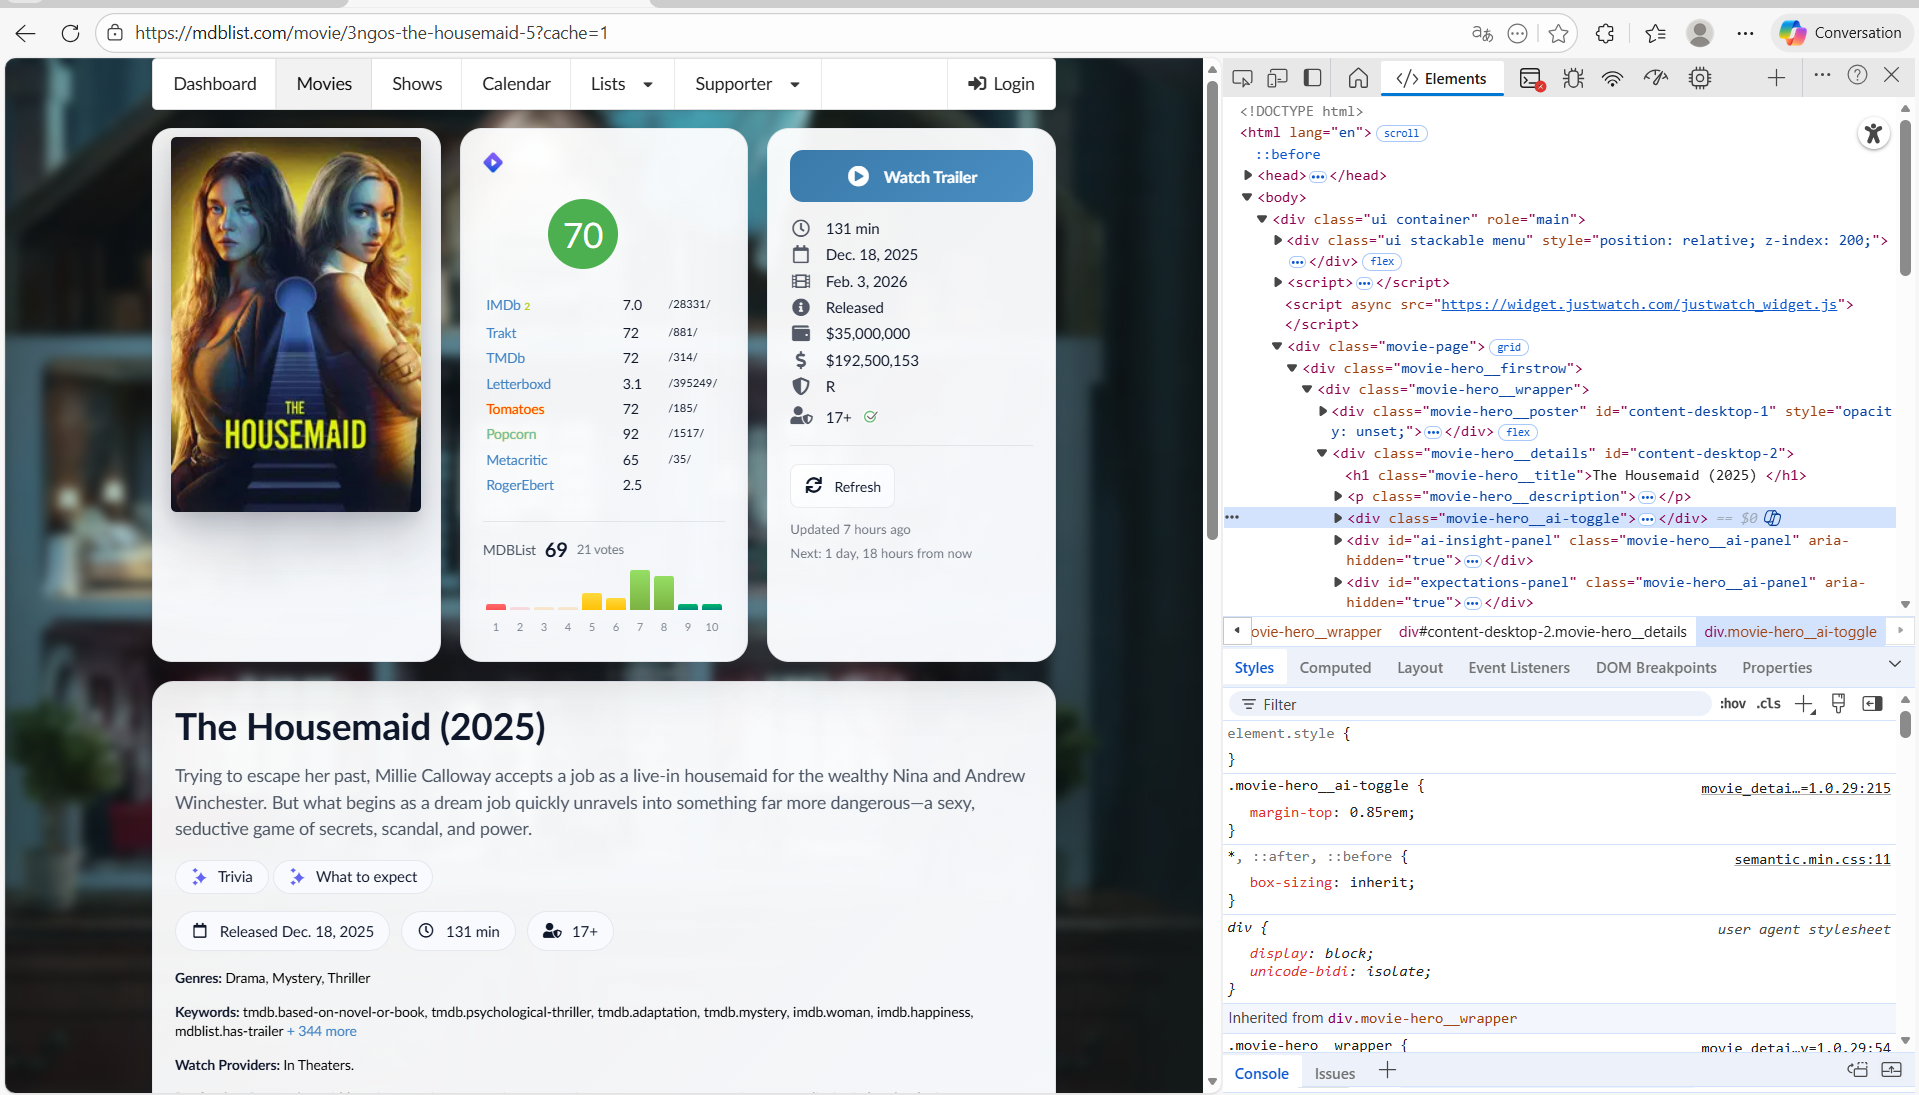

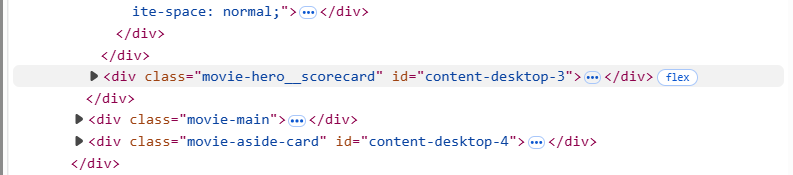

Pour trouver la note du film il faut aller dans la class "idscore" (voir image ci-dessous)

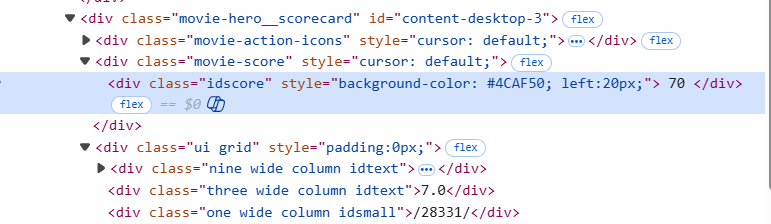

*Code pour récupérer la note du film*

In [ ]:
import requests
from bs4 import BeautifulSoup

url = 'https://mdblist.com/movie/3ngos-the-housemaid-5?cache=1'
headers = {
    "User-Agent": "user-agent-example/1.0 (https://example.com; contact@example.com)" #dans le cours sur le scrapping
}

response = requests.get(url, headers = headers)
soup = BeautifulSoup(response.content, "html.parser")
print(soup.find("div",class_="idscore"))
print(soup.find("div",class_="idscore").text.strip())   # le .text enlève toute la partie <div ...> et </div>
                                                        #le .strip enlève les espaces

<div class="idscore" style="background-color: #4CAF50; left:20px;">
              79
            </div>
79


*Test avec le 1er film du dataset*

Il faut trouver comment sont construits les urls pour chaque film (pour pouvoir faire une recherche par titre). Je fais un test avec le film Titanic (1er de la liste du premier dataset). En cherchant dans la barre de recherche je trouve l'url  suivant :

https://mdblist.com/movies/?q_title=Titanic&q_sort=&q_sortorder=asc&q_current_page=0&actor=&director=&yearf=&yeart=&yearr=&yearu=&q_score_input=0&q_score_input_max=100&q_rogerebert_input=0.0&q_rogerebert_input_max=4.0&q_imdbrating_input=0.0&q_imdbrating_input_max=10.0&q_imdbvotes_input=0&q_traktrating_input=0&q_traktrating_input_max=100&q_traktvotes_input=0&q_tmdbrating_input=0&q_tmdbrating_input_max=100&q_tmdbvotes_input=0&q_letterrating_input=0.0&q_letterrating_input_max=5.0&q_lettervotes_input=0&q_metacriticsrating_input=0&q_metacriticsrating_input_max=100&q_metacriticsvotes_input=0&q_tomatoesrating_input=0&q_tomatoesrating_input_max=100&q_tomatoesvotes_input=0&q_audiencerating_input=0&q_audiencerating_input_max=100&q_audiencevotes_input=0&q_anidbrating_input=0.0&q_anidbrating_input_max=10.0&q_anidbvotes_input=0&parental_nudity_min_i=0&parental_nudity_i=5&parental_violence_min_i=0&parental_violence_i=5&parental_language_min_i=0&parental_language_i=5&parental_drinking_min_i=0&parental_drinking_i=5&release_regions=&release_days_past=&release_days_future=&q_country=&q_country_x=&budget=&revenue=&production_country=&production_country_exclude=&q_runtime_min=&q_runtime_max=&q_list=&q_listx=&q_theater=&q_region=US&q_limit=&q_watched=&q_trakt_list_name=&q_trakt_list_desc=

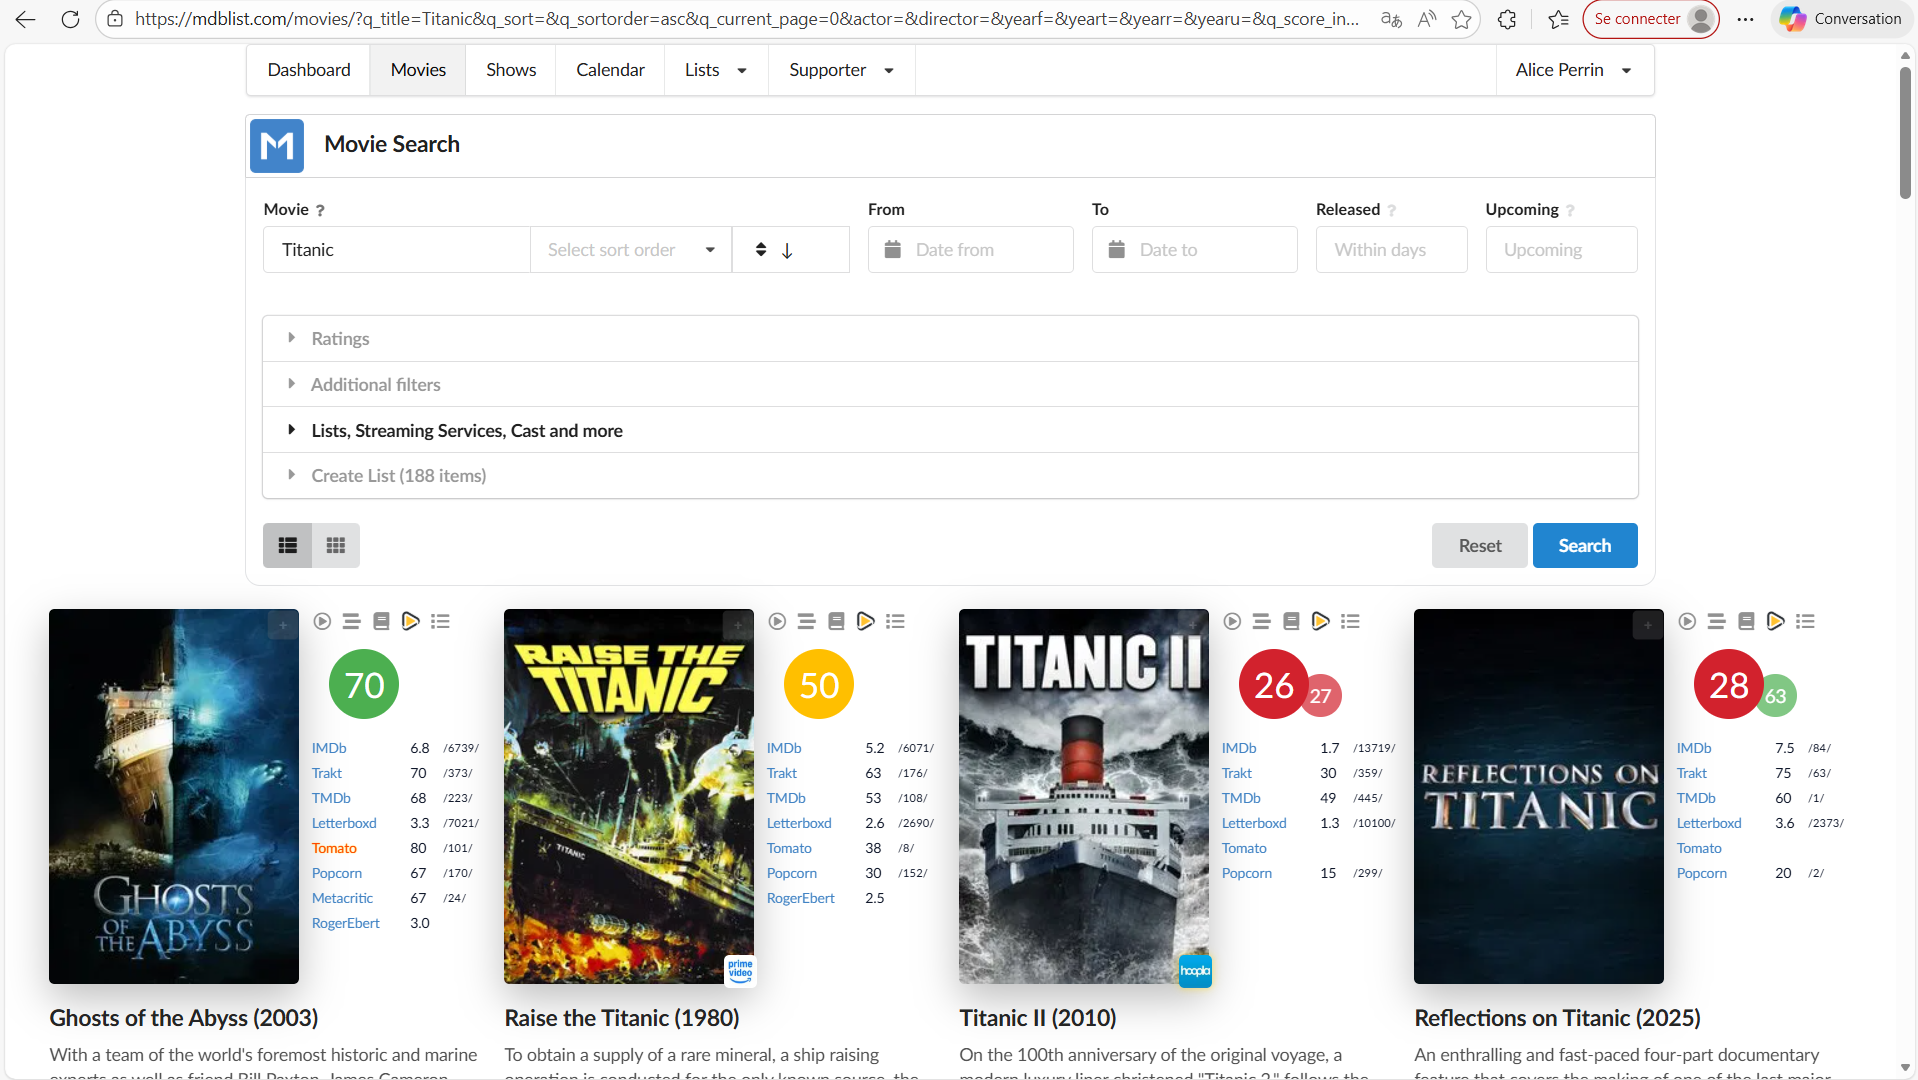

Il faut maintenant l'analyser. On a la première partie assez classique avec " https://mdblist.com/movies/ " puis on arrive à la partie concernant la requête avec "?q_title=Titanic". On peut donc adapter le code du cours pour retrouver la page qui s'affiche quand on fait la recherche pour "Titanic".

In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://mdblist.com/movies/"
headers = {
    "User-Agent": "user-agent-example/1.0 (https://example.com; contact@example.com)"
}

params = {
    "q_title": "Titanic"
}

response = requests.get(url, headers=headers, params=params)

soup = BeautifulSoup(response.content, "html.parser")

Sur la page de recherche, on a plusieurs résultats pour la même recherche. L'enjeu va donc être de trouver le bon film pour chaque recherche. Comme dans notre dataset on a le titre mais aussi l'année, on va pouvoir filtrer pour trouver le film qui correspond. Dans l'url, on a  "&yearf=&yeart" pour year from et year to.

In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://mdblist.com/movies/"
headers = {
    "User-Agent": "user-agent-example/1.0 (https://example.com; contact@example.com)"
}

params = {
    "q_title": "Titanic",
    "yearf" :"1997",
    "yeart" :"1997"
}

response = requests.get(url, headers=headers, params=params)

soup = BeautifulSoup(response.content, "html.parser")

C'est finalement trop compliqué car il y a plusieurs films avec le même titre et la même année. De plus, l'année de sortie du film n'est pas la même en France (date du dataset de data.gouv) et aux Etats-Unis (date du site mdblist).
On va donc rajouter manuellement les notes pour les films pour lesquels le scraping atteint ses limites (avec les paramètres que nous avons entrés).

*Scraping pour tout le dataset*

Le prochain objectif est d'aller chercher le titre et la date du film dans le dataset du data.gouv pour que la recherche de la page commence à être "automatisée". Le premier problème c'est les dates de sortie qui sont celles des Etats-Unis sur imdb et de France dans le dataset. On va donc mettre de 1996 à 1998 pour être sûrs d'avoir le bon film.

In [ ]:
import requests
from bs4 import BeautifulSoup
titre_1=str(data_1.iloc[0]['titre'])
annee_1_0=str(data_1.iloc[0]['année de sortie']-1)
annee_1_1=str(data_1.iloc[0]['année de sortie']+1)

url = "https://mdblist.com/movies/"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

params = {
    "q_title": titre_1,
    "yearf" :annee_1_0,
    "yeart" :annee_1_1
}

response = requests.get(url, headers=headers, params=params)

soup = BeautifulSoup(response.content, "html.parser")
print(soup.find("div",class_="idscore"))
print(soup.find("div",class_="idscore").text.strip())


<div class="idscore search-score-main" style="background-color: #4CAF50;">
            70
          </div>
70


In [ ]:
import requests
from bs4 import BeautifulSoup
titre_1=str(data_1.iloc[0]['titre'])
annee_1_0=str(data_1.iloc[0]['année de sortie']-1)
annee_1_1=str(data_1.iloc[0]['année de sortie']+1)

url = "https://mdblist.com/movies/"
headers = {
    "User-Agent": "user-agent-example/1.0 (https://example.com; contact@example.com)"
}

params = {
    "q_title": titre_1,
    "yearf" :annee_1_0,
    "yeart" :annee_1_1,

}

response = requests.get(url, headers=headers, params=params)
soup = BeautifulSoup(response.content, "html.parser")

premier_film = soup.find("div", class_="idscore search-score-main")
print(premier_film)



<div class="idscore search-score-main" style="background-color: #4CAF50;">
            70
          </div>


*Code pour obtenir la note pour le reste des films (ceux sans doublons)*

In [ ]:
import requests
from bs4 import BeautifulSoup
titre_1=str(data_1.iloc[2]['titre'])

url = "https://mdblist.com/movies/"
headers = {
    "User-Agent": "user-agent-example/1.0 (https://example.com; contact@example.com)"
}

params = {
    "q_title": titre_1,

}

response = requests.get(url, headers=headers, params=params)
soup = BeautifulSoup(response.content, "html.parser")

premier_film = soup.find("div", class_="idscore search-score-main").text.strip()
print(premier_film)


77


Ce code fonctionne pour les autres films (ceux sans doublons) donc il ne reste plus qu'à faire une boucle pour parcourir toutes les lignes du tableau (les films), récupérer les notes des films et créer une nouvelle colonne 'note' avec les notes des différents films.

In [ ]:
import requests
from bs4 import BeautifulSoup
#titre_1=str(data_1.iloc[2]['titre'])

url = "https://mdblist.com/movies/"
headers = {
    "User-Agent": "user-agent-example/1.0 (https://example.com; contact@example.com)"
}
for i in range(len(data_1)):
  titre=str(data_1.iloc[i]['titre'])
  params = {
      "q_title": titre,

  }

  response = requests.get(url, headers=headers, params=params)
  soup = BeautifulSoup(response.content, "html.parser")

  film = soup.find("div", class_="idscore search-score-main").text.strip()
  print(film)

70
70
77
82
87
81
83
75
80
78
28
52
63
87
72


AttributeError: 'NoneType' object has no attribute 'text'

On crée maintenant une liste de toutes les notes. On va changer manuellement la note de Titanic car problème avec les doublons.

In [ ]:
print(data_1.iloc[13])

3
rang                                           14
titre                  Le Pont de la rivière Kwai
réalisateur                               D. Lean
année de sortie                              1957
nationalité1                                   GB
entrées (millions)2                      13477407
Name: 13, dtype: object


En fait, il y en a plusieurs avec des doublons. Il faut voir si juste avec des dates on arrive à avoir les bons films ou s'il faut changer manuellement tous ceux avec de doublons.

In [ ]:
import requests
from bs4 import BeautifulSoup

liste_des_notes=[]

url = "https://mdblist.com/movies/"
headers = {
    "User-Agent": "user-agent-example/1.0 (https://example.com; contact@example.com)"
}
for i in range(len(data_1)):
  titre=str(data_1.iloc[i]['titre'])
  annee_0=str(data_1.iloc[i]['année de sortie']-1)
  annee_1=str(data_1.iloc[i]['année de sortie']+1)
  params = {
      "q_title": titre,
      "yearf" :annee_0,
      "yeart" :annee_1,

  }

  response = requests.get(url, headers=headers, params=params)
  soup = BeautifulSoup(response.content, "html.parser")
  note_film = soup.find("div", class_="idscore search-score-main")

  if note_film:
    note = note_film.text.strip()
    liste_des_notes.append(note)
  else:
    liste_des_notes.append("N/A")


data_1['Note']=liste_des_notes
data_1.head()


3,rang,titre,réalisateur,année de sortie,nationalité1,entrées (millions)2,Note
0,1,Titanic,J. Cameron,1998,US,22319783,70
1,2,Bienvenue chez les Ch'tis,D. Boon,2008,FR,20445308,70
2,3,Intouchables,"E. Tolédano, O. Nakache",2011,FR,19511427,77
3,4,La Grande Vadrouille,G. Oury,1966,FR/GB,17331552,82
4,5,Autant en emporte le vent,V. Fleming,1950,US,16730059,87


*Vérification des notes attribuées par le code*

In [ ]:
data_1['Note'][199]
#data_1['titre'][135]

'56'

Liste des films avec indices pour lesquels les notes ne sont pas les bonnes :  index : Titre du film -> note du code / vraie note du site  
- 0 : Titanic -> 70 / 80 (mettre *manuellement*)
- 8 : Le livre de la jungle -> 79 / 76 (pbm de dates)
- 10 : Les Dix Commandements -> 28 / 80 (pbm de dates)
- 11 : Ben Hur -> 52 / 80 (pbm de dates)
- 14 : Cendrillon -> 72 / 77 (pbm de dates)
- 15 : Avatar, la voie de l'eau -> N/A / 77
- 21 : La Belle et le Clochard -> 55 / 76
- 23 : Bambi -> 59 / 77 (pbm de dates mais à 4 ans de décalage)
- 27 : Trois hommes et un couffin -> N/A / rien -> note allociné : 70
- 30 : La guerre des boutons -> 48 / 63 (pbm de dates)
- 31 : Les Misérables -> 71 / 48
- 33 : Le Roi Lion -> 86 / 67 (pbm de dates)
- 39 : Le Comte de Monte Cristo -> 66 / 83 (pbm de dates)
- 40 : Le Diner de Cons -> 55 / 78 (pbm de dates)
- 48 : La Grande Evasion -> 66 / 85
- 49 : Le Bataillon du ciel -> ? / ? (mettre *manuellement* la moyenne des 2 notes : 58)
- 52 : Le Dictateur -> 60 / 86 (pbm de dates)
- 53 : Vice-Versa 2 -> 87 / 78 (pbm de dates)
- 56 : Violettes impériales -> ? / 57
- 58 : Le Boulanger de Valorgue -> ? / 64
- 60 : Pinocchio -> 37 / 82 (pbm de dates)
- 61 : L'Age de Glace, le temps des dinosaures -> N/A / 64
- 63 : Tarzan -> 53 / 80 (pbm de dates)
- 65 : Le Comte de Monte Cristo -> 66 / 33 (pbm de dates)
- 66 : Sixième Sens -> 77 / 79 (pbm de dates)
- 71 : Orange Mécanique -> ? /78 (pbm de dates)
- 72 : La Reine des Neiges 2 -> 75 / 74 (pbm de dates)
- 77 : La Vérité si je mens 2 -> 53 / 48 (pbm de dates)
- 78 : Aladdin -> 50 / 83 (mettre *manuellement* car trop compliqué)
- 79 : Les Aventures de Peter Pan -> ? / 74 (mettre *manuellement* car pbm avec titre)
- 84 : Jean de Florette -> 82 / 83 (mettre *manuellement* car 2 films à la même date)
- 88 : Shrek 2 -> 85 / 76 (mettre *manuellement* car 4 films dans les mêmes années)
- 93 : Monsieur Vincent -> 29 / 63 (mettre *manuellement* car pbm dans calcul de leur moyenne)
- 94 : Le Seigneur des Anneaux - la communauté de l'anneau -> ? / 87 (pbm dans la recherche à mettre *manuellement*)
- 95 : Les Sept Mercenaires -> 44 / 63 (à mettre *manuellement* car pbm dans la recherche)
- 101 : Michel Strogoff -> ? / 60 ( à mettre *manuellement* car pbm calcul de leur moyenne)
- 103 : Le Bossu de Notre-Dame -> 40 / 76 (pbm de dates)
- 105 : Mission Spéciale -> 25 / 53 (à mettre *manuellement* car pbm calcul de leur moyenne)
- 108 : Fanfan la Tulipe -> 41 / 57 (pbm de dates)
- 113 : Vaiana 2 -> 82 / 64 (pbm dates)
- 114 : Goldfinger -> 73 / 84 (pbm dates)
- 117 :  Nous irons à Paris -> ? /57 (mettre *manuellement* car pbm dans leur affichage)
-124 : La Belle au bois dormant -> 37 / 77 (pbm de dates)
-126 : Robin des Bois -> 57 / 70 (pbm de dates)
- 127 : Taxi -> 65 / 71 (mettre *manuellement* car trop de films à la même date)
- 135 : Spider-Man -> 59 / 74 (pbm de dates et peut-être trop de titres pareils aussi)
- 138 : Ivanhoé -> 56 / 66 (pbm de dates)
- 147 : Pas si bête -> ? / 61 (à mettre *manuellement* car pbm sur leur site)
- 150 : La chartreuse de parme -> ? / 69 (à mettre *manuellement* car pbm sur leur site)
- 152 : Le père tranquille -> ? / 65 (à mettre *manuellement* car pbm sur leur site)
- 154 : Oscar -> 83 / 73 (à mettre *manuellement* car 2 films avec même année)
- 155 : Harry Potter 7 partie 2 -> N/A / 75 (à mettre *manuellement*)
- 156 : Taxi 3 -> 65 / 57 (pbm de dates)
- 157 : Star wars 9 -> N/A / 61 (à mettre *manuellement*)
- 164 : Guerre et Paix -> 47 /61 (mettre *manuellement* car trop de films à la même date)
- 166 : Barbie -> 42 / 77 ( pbm dates)
- 167 :L'Odyssée du Docteur Wassel -> N/A /66 (à mettre *manuellement*)
- 178 : Moi, moche et méchant 3 -> 75 / 55 (à mettre *manuellement* car trop de films pareils)
- 179 : Les indestructibles 2 -> 83 / 79 (à mettre *manuellement*)
- 183 : Andalousie -> ? / 50 (à mettre *manuellement*)
- 189 : La Vérité -> 77/59 (pbm de dates)
- 190 : Notre-Dame de Paris -> 58 /47 (pbm de dates)
- 193 : Les Tuche 3 -> 48 / 36 (à mettre *manuellement* car trop de films avec même titre)
- 197 : Bons baisers de Russie -> 26/78 (pbms de date)
-198 : Star wars 2 -> N/A / 60(à mettre *manuellement*)
- 199 : Joker -> 56 / 73 (pbms de dates)


In [ ]:
data_1.loc[0, 'Note'] = 80
data_1.loc[8, 'Note'] = 76
data_1.loc[10, 'Note'] = 80
data_1.loc[11, 'Note'] = 80
data_1.loc[14, 'Note'] = 77
data_1.loc[15, 'Note'] = 77
data_1.loc[21, 'Note'] = 76
data_1.loc[23, 'Note'] = 77
data_1.loc[27, 'Note'] = 70
data_1.loc[30, 'Note'] = 63
data_1.loc[31, 'Note'] = 48
data_1.loc[33, 'Note'] = 67
data_1.loc[39, 'Note'] = 83
data_1.loc[40, 'Note'] = 78
data_1.loc[48, 'Note'] = 85
data_1.loc[49, 'Note'] = 58
data_1.loc[52, 'Note'] = 86
data_1.loc[53, 'Note'] = 78
data_1.loc[56, 'Note'] = 57
data_1.loc[58, 'Note'] = 64
data_1.loc[60, 'Note'] = 82
data_1.loc[61, 'Note'] = 64
data_1.loc[63, 'Note'] = 80
data_1.loc[65, 'Note'] = 33
data_1.loc[66, 'Note'] = 79
data_1.loc[71, 'Note'] = 78
data_1.loc[72, 'Note'] = 74
data_1.loc[77, 'Note'] = 48
data_1.loc[78, 'Note'] = 83
data_1.loc[79, 'Note'] = 74
data_1.loc[84, 'Note'] = 83
data_1.loc[88, 'Note'] = 76
data_1.loc[93, 'Note'] = 63
data_1.loc[94, 'Note'] = 87
data_1.loc[101, 'Note'] = 60
data_1.loc[103, 'Note'] = 76
data_1.loc[105, 'Note'] = 53
data_1.loc[108, 'Note'] = 57
data_1.loc[113, 'Note'] = 64
data_1.loc[114, 'Note'] = 84
data_1.loc[117, 'Note'] = 57
data_1.loc[127, 'Note'] = 74
data_1.loc[135, 'Note'] = 74
data_1.loc[138, 'Note'] = 66
data_1.loc[147, 'Note'] = 61
data_1.loc[150, 'Note'] = 69
data_1.loc[152, 'Note'] = 65
data_1.loc[154, 'Note'] = 73
data_1.loc[156, 'Note'] = 57
data_1.loc[157, 'Note'] = 61
data_1.loc[164, 'Note'] = 61
data_1.loc[166, 'Note'] = 77
data_1.loc[167, 'Note'] = 66
data_1.loc[178, 'Note'] = 55
data_1.loc[179, 'Note'] = 79
data_1.loc[183, 'Note'] = 50
data_1.loc[189, 'Note'] = 59
data_1.loc[190, 'Note'] = 47
data_1.loc[193, 'Note'] = 36
data_1.loc[197, 'Note'] = 78
data_1.loc[199, 'Note'] = 73

In [ ]:
data_1.head()

3,rang,titre,réalisateur,année de sortie,nationalité1,entrées (millions)2,Note
0,1,Titanic,J. Cameron,1998,US,22319783,80
1,2,Bienvenue chez les Ch'tis,D. Boon,2008,FR,20445308,70
2,3,Intouchables,"E. Tolédano, O. Nakache",2011,FR,19511427,77
3,4,La Grande Vadrouille,G. Oury,1966,FR/GB,17331552,82
4,5,Autant en emporte le vent,V. Fleming,1950,US,16730059,87


*Rajout de la durée du film par scraping*

Dans la page du film

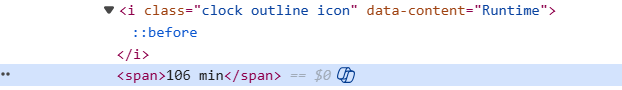

Dans la page de la recherche

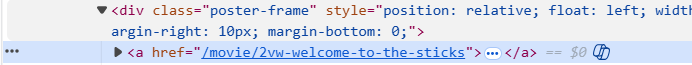

In [ ]:
import requests
from bs4 import BeautifulSoup
titre_1=str(data_1.iloc[0]['titre'])
annee_1_0=str(data_1.iloc[0]['année de sortie']-1)
annee_1_1=str(data_1.iloc[0]['année de sortie']+1)
url = "https://mdblist.com/movies/"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

params = {
    "q_title": titre_1,
    "yearf" :annee_1_0,
    "yeart" :annee_1_1
}

response = requests.get(url, headers=headers, params=params)

soup = BeautifulSoup(response.content, "html.parser")
class_poster_frame= soup.find("div", class_="poster-frame")
lien_film_1=class_poster_frame.find("a", href=True)    #on obtient la partie 'en plus' du lien complet pour aller sur la page du film -> donc pouvoir accéder à la durée

url_film = url[:-8]
lien_film_tot = url_film + lien_film_1['href']   #on obtient le lien de la page du film recherché

response_film = requests.get(lien_film_tot, headers=headers)
soup_film = BeautifulSoup(response_film.content, "html.parser")
icon_runtime = soup_film.find("i", attrs={"data-content": "Runtime"})    #La balise n'est plus "div" mais "i" /  attrs pour trouver avec dictionnaire

duree_minute = icon_runtime.find_next_sibling("span").text.strip()         #pour aller dans <span> </span>
duree_int=int(duree_minute[:-4])                                          #Pour enlever le 'min' après la durée
print(duree_int)

91


In [ ]:
import requests
from bs4 import BeautifulSoup

liste_des_notes=[]
liste_des_durees=[]

url = "https://mdblist.com/movies/"
headers = {
    "User-Agent": "user-agent-example/1.0 (https://example.com; contact@example.com)"
}
for i in range(len(data_1)):
  titre=str(data_1.iloc[i]['titre'])
  annee_0=str(data_1.iloc[i]['année de sortie']-1)
  annee_1=str(data_1.iloc[i]['année de sortie']+1)
  params = {
      "q_title": titre,
      "yearf" :annee_0,
      "yeart" :annee_1,

  }

  response = requests.get(url, headers=headers, params=params)
  soup = BeautifulSoup(response.content, "html.parser")
  note_film = soup.find("div", class_="idscore search-score-main")

  if note_film:
    note = note_film.text.strip()
    liste_des_notes.append(note)
  else:
    liste_des_notes.append("N/A")

  class_poster_frame= soup.find("div", class_="poster-frame")
  if class_poster_frame:
    lien_film_1=class_poster_frame.find("a", href=True)
    url_film = url[:-8]
    lien_film_tot = url_film + lien_film_1['href']
    response_film = requests.get(lien_film_tot, headers=headers)
    soup_film = BeautifulSoup(response_film.content, "html.parser")
    icon_runtime = soup_film.find("i", attrs={"data-content": "Runtime"})
    duree_minute = icon_runtime.find_next_sibling("span").text.strip()
    duree_film=int(duree_minute[:-4])

    if duree_film:
        duree = duree_film
        liste_des_durees.append(duree)
    else:
        liste_des_durees.append("N/A")
  else:
    liste_des_durees.append("N/A")

data_1['Note']=liste_des_notes
data_1['Durée (en min)']=liste_des_durees

data_1.head()

3,rang,titre,réalisateur,année de sortie,nationalité1,entrées (millions)2,Note,Durée (en min)
0,1,Titanic,J. Cameron,1998,US,22319783,70,91
1,2,Bienvenue chez les Ch'tis,D. Boon,2008,FR,20445308,70,106
2,3,Intouchables,"E. Tolédano, O. Nakache",2011,FR,19511427,77,113
3,4,La Grande Vadrouille,G. Oury,1966,FR/GB,17331552,82,132
4,5,Autant en emporte le vent,V. Fleming,1950,US,16730059,87,233


In [ ]:
data_1.loc[0, 'Durée (en min)'] = 194
data_1.loc[8, 'Durée (en min)'] = 78
data_1.loc[10, 'Durée (en min)'] = 220
data_1.loc[11, 'Durée (en min)'] = 212
data_1.loc[14, 'Durée (en min)'] = 74
data_1.loc[15, 'Durée (en min)'] = 192
data_1.loc[21, 'Durée (en min)'] = 76
data_1.loc[23, 'Durée (en min)'] = 69
data_1.loc[27, 'Durée (en min)'] = 106
data_1.loc[30, 'Durée (en min)'] = 90
data_1.loc[31, 'Durée (en min)'] = 210
data_1.loc[39, 'Durée (en min)'] = 178
data_1.loc[40, 'Durée (en min)'] = 80
data_1.loc[48, 'Durée (en min)'] = 173
data_1.loc[49, 'Durée (en min)'] = 123
data_1.loc[52, 'Durée (en min)'] = 125
data_1.loc[53, 'Durée (en min)'] = 97
data_1.loc[56, 'Durée (en min)'] = 94
data_1.loc[58, 'Durée (en min)'] = 103
data_1.loc[60, 'Durée (en min)'] = 88
data_1.loc[61, 'Durée (en min)'] = 94
data_1.loc[63, 'Durée (en min)'] = 88
data_1.loc[65, 'Durée (en min)'] = 183
data_1.loc[66, 'Durée (en min)'] = 107
data_1.loc[71, 'Durée (en min)'] = 137
data_1.loc[72, 'Durée (en min)'] = 103
data_1.loc[77, 'Durée (en min)'] = 105
data_1.loc[78, 'Durée (en min)'] = 92
data_1.loc[79, 'Durée (en min)'] = 77
data_1.loc[84, 'Durée (en min)'] = 121
data_1.loc[88, 'Durée (en min)'] = 92
data_1.loc[93, 'Durée (en min)'] = 111
data_1.loc[94, 'Durée (en min)'] = 179
data_1.loc[95, 'Durée (en min)'] = 132
data_1.loc[101, 'Durée (en min)'] = 109
data_1.loc[103, 'Durée (en min)'] = 91
data_1.loc[105, 'Durée (en min)'] = 183
data_1.loc[108, 'Durée (en min)'] = 102
data_1.loc[113, 'Durée (en min)'] = 100
data_1.loc[114, 'Durée (en min)'] = 110
data_1.loc[117, 'Durée (en min)'] = 93
data_1.loc[124, 'Durée (en min)'] = 194
data_1.loc[126, 'Durée (en min)'] = 83
data_1.loc[127, 'Durée (en min)'] = 86
data_1.loc[135, 'Durée (en min)'] = 121
data_1.loc[138, 'Durée (en min)'] = 137
data_1.loc[147, 'Durée (en min)'] = 100
data_1.loc[150, 'Durée (en min)'] = 170
data_1.loc[152, 'Durée (en min)'] = 95
data_1.loc[154, 'Durée (en min)'] = 80
data_1.loc[155, 'Durée (en min)'] = 130
data_1.loc[156, 'Durée (en min)'] = 87
data_1.loc[157, 'Durée (en min)'] = 141
data_1.loc[164, 'Durée (en min)'] = 208
data_1.loc[166, 'Durée (en min)'] = 114
data_1.loc[167, 'Durée (en min)'] = 140
data_1.loc[178, 'Durée (en min)'] = 90
data_1.loc[179, 'Durée (en min)'] = 118
data_1.loc[183, 'Durée (en min)'] = 94
data_1.loc[193, 'Durée (en min)'] = 92
data_1.loc[197, 'Durée (en min)'] = 115
data_1.loc[198, 'Durée (en min)'] = 142
data_1.loc[199, 'Durée (en min)'] = 122



In [ ]:
data_1.head()

*Mettre les colonnes de textes en valeurs numériques*

Il faut mettre la colonne du genre en valeur numérique.

In [ ]:
genres_differents ={}
compteur=0
liste_num = []

for genre in data_1['genre']:
  if genre not in genres_differents:
    genres_differents[genre]= compteur
    compteur = compteur + 1
  liste_num.append(genres_differents[genre])
data_1['genre_num']= liste_num
print(genres_differents)

KeyError: 'genre'

On a donc les catégories:
- Romance représentée par 0
- Comédie représentée par 1
- Comédie dramatique représentée par 2
- Science-Fiction représentée par 3
- Western représentée par 4
- Animation représentée par 5
- Historique représentée par 6
- Action représentée par 7
- Drame représentée par 8
- Aventure représentée par 9
- Fantastique représentée par 10
- Erotique représentée par 11
- Comédie musicale représentée par 12
- Thriller représentée par 13
- Horreur représentée par 14



In [ ]:
display(data_1[['titre','genre','genre_num']])

KeyError: "['genre', 'genre_num'] not in index"

Même raisonnement pour les nationnalités

In [ ]:
nationalites_differentes ={}
compteur=0
liste_num_nationalite = []

for nationalite in data_1['nationalité1']:
  if nationalite not in nationalites_differentes:
    nationalites_differentes[nationalite]= compteur
    compteur = compteur + 1
  liste_num_nationalite.append(nationalites_differentes[nationalite])
data_1['nationalité_num']= liste_num_nationalite

print(nationalites_differentes)

On a 2 catégories différentes IT/FR et FR/IT alors que c'est la même catégorie. On va donc changer le IT/FR par FR/IT pour n'avoir qu'une seule valeur numérique pour cette catégorie.

In [ ]:
nationalites_differentes ={}
compteur=0
liste_num_nationalite = []

data_1['nationalité1']=data_1['nationalité1'].replace('IT/FR','FR/IT')
for nationalite in data_1['nationalité1']:
  if nationalite not in nationalites_differentes:
    nationalites_differentes[nationalite]= compteur
    compteur = compteur + 1
  liste_num_nationalite.append(nationalites_differentes[nationalite])
data_1['nationalité_num']= liste_num_nationalite

print(nationalites_differentes)

NameError: name 'data_1' is not defined

On a donc les catégories :    
- Etats-Unis (US) représentée par 0
- France (FR) représentée par 1
- France/Angleterre (FR/GB) représentée par 2
- Italie (IT) représentée par 3
- Angleterre (GB) représentée par 4
- Italie/France (IT/FR) représentée par 5
- France/Allemagne/Italie (FR/DE/IT) représentée par 6
- France/Allemagne (FR/DE) représentée par 7
- France/Chine (FR/CH) représentée par 8
- France/Belgique (FR/BE) représentée par 9
- France/Espagne (FR/ES) représentée par 10
- Nouvelle-Zélande (NZ) représentée par 11
- France/Méxique (FR/MX) représentée par 12
- France/Allemagne/Espagne/Italie représentée par 13
- Autriche (AT) représentée par 14
- Afrique du Sud (ZA) représentée par 15
- Australie (AU) représentée par 16

In [ ]:
display(data_1[['titre','nationalité1','nationalité_num']])

###Prédiction du nombre d'entrées

Le but est de faire une prédiction sur le nombre d'entrées d'un film en donnant comme paramètres :    
- l'année de sortie,
- le genre,
- la nationalité,
- la note,
- la durée

Comme le nombre d'entrées est continu on va utiliser une régression et pas une classification.
On va mettre en entrées (la ligne):
- nationalité_num
- genre_num
- note
- durée (en min)
- année de sortie

La sortie sera (la colonne): le nombre d'entrées (en millions).

En suivant le cours, on va séparer le tableau pour avoir la partie du 'training' (de l'entraînement) et la partie du 'test' pour voir si le code arrive à prédire le nombre d'entrées de films dont on connait déjà le nombre d'entrées.

On va commencer par la régression linéaire qui est le modèle le plus simple.

Documentation sur le site : https://www.datacamp.com/fr/tutorial/linear-regression-in-python

*Division du tableau*

In [ ]:
tableau_divise = data_1.drop([45, 98, 145, 172]) #on enlève 5 lignes au hasard juste pour
#pouvoir faire des tests sur ces films-là ensuite

*Données pour évaluer la régression*

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

parametres = ['année de sortie', 'Note', 'Durée (en min)', 'genre_num', 'nationalité_num']
x = tableau_divise[parametres]
y = tableau_divise['entrées (millions)2']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)
#On prend 20% des lignes pour le test
#random_state permet de relancer toujours le même aléatoire (comme set.seed())

model= LinearRegression()
model.fit(x_train,y_train)

y_pred = model.predict(x_test)

r_carre = r2_score(y_test, y_pred)
print("R^2:", r_carre)

# RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Racine de l'erreur quadratique (RMSE):", rmse)

# MAE
mae = mean_absolute_error(y_test, y_pred)
print("Erreur absolue moyenne (MAE):", mae)

- On trouve un R^2 = 0.16 ce qui est très bas. Pour avoir une prédiction parfaite on doit avoir R^2 = 1. Donc on a en fait une régression qui représente réellement 16%.
- On trouve une racine de l'erreur quadratique de 2 308 238. La racine est très sensible aux valeurs extrêmes.
- On trouve l'erreur absolue moyenne de 1 883 705. Cette métrique est moins sensible aux grandes valeurs.

Maintenant qu'on a une régression linéaire plus ou moins satisfaisante, on va créer un code qui permet de renvoyer le nombre d'entrées d'un film avec les paramètres à donner en entrée.

In [ ]:
print("Entrer les informations du film :")

annee_film = int(input("Année de sortie :"))
print("\n")
note_film = int(input("Note sur 100 :"))
print("\n")
duree_film = int(input("Durée (en min) :"))
print("\n")
print("Pour le genre, les choix sont : 0-Romance, 1-Comédie, 2-Comédie dramatique, 3-Science-Fiction, 4-Western, 5-Animation, \n 6-Historique, 7-Action, 8-Drame, 9-Aventure, 10-Fantastique, 11-Erotique, 12-Comédie musicale, 13-Thriller, 14- Horreur")
print("\n")
genre_film = int(input("Genre :"))
print("\n")
print("Pour la nationalité, les choix sont : 0-Etats-Unis, 1-France, 2-France/Grande-Bretagne, 3-Italie, 4-Grande-Bretagne, 5-Italie/France,\n 6-France/Italie, 7-France/Allemagne/Italie, 8-France/Allemagne, 9-France/Chine, 10-France/Belgique, 11-France/Espagne, 12-Nouvelle-Zélande, 13-France/Mexique, \n 14-France/Allemagne/Espagne/Italie, 15-Autriche, 16-Afrique du Sud, 17-Australie")
print("\n")
nationalite_film=int(input("Nationalité :"))
print("\n")

film_a_estimer = pd.DataFrame({
    'année de sortie': [annee_film],
    'Note': [note_film],
    'Durée (en min)': [duree_film],
    'genre_num' : [genre_film],
    'nationalité_num' : [nationalite_film]
})
prediction = model.predict(film_a_estimer)
prediction_int = int(prediction[0])
print("Le film a un nombre d'entrées est d' environ",prediction_int)

Test avec le film Hollywoo :    
- année : 2011
- note allociné : 50  
- durée : 107
- genre : comédie -> 1
- nationalité : france -> 1

On obtient 7 799 565 d'entrées pour le film Hollywoo. En réalité, le film a fait 2 350 666 d'entrées.

Il faut tester avec d'autres films mais la prédiction semble biaisée. Cela peut s'expliquer par le fait que la régression se base sur un tableau qui prend les 200 films qui ont fait le plus d'entrées en France donc le modèle ne sait pas vraiment gérer les films moins connus (qui ont fait moins d'entrées).

Plusieurs raisons peuvent expliquer ce résultat :

- Un jeu de données trop petit : le dataset est limité, ce qui ne permet pas d'entraîner correctement le modèle, même s'il s'agit d'une régression linéaire simple.

- Une relation non linéaire : les données ne semblent pas suivre une tendance linéaire claire, ce qui pose la question de l'adéquation de la régression linéaire pour ce problème.


Les tests faits avec d'autres films (avec genres différents) :    
- The Holiday (note de imdblist) : 9 476 195 entrées prédites par le modèle contre 1 001 122 entrées réelles.
- Zootopie (avec la note attribuée par allociné) : 8 676 344 entrées prédites par le modèle contre 6 547 287 entrées réelles.
- Forrest Gump (note de imdblist) : 10 094 358 entrées prédites par le modèle contre 3 963 919 entrées réelles.
- Interstellar (note de imdblist) : 10 071 175 entrées prédites par le modèle contre 2 640 439 entrées réelles.
- The Hateful Eight (note de imdblist) : 9 120 196 entrées prédites contre 1 779 974 entrées réelles.
- Toy Story (note de imdblist) : 8 607 198 entrées prédites contre  2 729 174 entrées réelles.
- 1917 (note de imdblist) : 8 400 537 entrées prédites contre 2 203 337 entrées réelles.
- Die Hard (note de imdblist) : 8 582 315 entrées prédites contre 655 545 entrées réelles.
- Le Pianiste (note d'allociné) : 8 167 546 entrées prédites contre 1 099 208 entrées réelles.

On remarque une grande surévaluation du nombre d'entrées.

On va tester un autre modèle pour voir si il fonctionne mieux. Après quelques recherches, on a trouvé que le modèle de forêt aléatoire fonctionne mieux que la régression linéaire.

*Modèle Random Forest*

Lien documentation Forêt Aléatoire : https://www.stat4decision.com/fr/foret-aleatoire-avec-python/

In [ ]:
from sklearn.ensemble import RandomForestRegressor
model_f = RandomForestRegressor(
    n_estimators =100,
    random_state = 1)
model_f.fit(x_train, y_train)
y_pred_f = model_f.predict(x_test)
pd.DataFrame(model_f.feature_importances_,
              index = x_train.columns,
              columns = ["importance"]).sort_values(
     "importance",
     ascending = False)


NameError: name 'x_train' is not defined

On remarque que la nationalité et le genre n'ont pas beaucoupp d'importance contrairement à l'année de sortie, la durée et la note. Pour la note, cela semble assez logique mais si certains films n'ont pas eu beaucoup de succès à leur sortir (donc nombre d'entrées faible) mais ils ont eu du succès par la suite.

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error
r_carre_f = r2_score(y_test, y_pred_f)
print("R^2:", r_carre_f)

# RMSE
rmse_f = np.sqrt(mean_squared_error(y_test, y_pred_f))
print("Racine de l'erreur quadratique (RMSE):", rmse_f)

# MAE
mae_f = mean_absolute_error(y_test, y_pred_f)
print("Erreur absolue moyenne (MAE):", mae_f)

On trouve un R^2 encore plus petit (9%). Cela est dû à la taille de notre dataset. Le modèle de Random Forest est plus complexe mais fonctionne mieux sur des grands jeux de données.

Il était tout de même intéressant de tester un nouveau modèle afin de voir les différences. Surtout que la partie code n'est pas beaucoup plus complexe car on reprend beaucoup d'éléments du modèle de régression linéaire.

#Conclusion

Conclusion et interpretation sur ma partie
- Youssef Rais

L'analyse montre qu'en France, la fréquentation des cinémas connaît une remontée depuis la crise du Covid-19, après la chute brutale observée en 2020. Toutefois, cette reprise reste fragile et se heurte à plusieurs difficultés majeures.

D'abord, la montée en puissance des plateformes de streaming, capables d'investir des budgets très élevés, intensifie la concurrence et modifie durablement les habitudes de consommation culturelle. Ensuite, la fréquentation des salles est aussi freinée par des facteurs sociaux : la hausse du coût de la vie, l'inflation et l'augmentation de la pauvreté peuvent réduire l'accès au cinéma pour une partie de la population.

Enfin, l'étude spatiale menée sur Lyon met en évidence une forme de ségrégation territoriale : la concentration des cinémas dans certaines zones semble favoriser davantage les quartiers et publics les plus aisés, ce qui peut accentuer les inégalités d'accès à l'offre culturelle


Ce projet m'a personnellement beaucoup apporté. Il m'a permis d'apprendre à travailler en équipe avec des camarades sérieux et investis, et à mieux organiser le travail collectif. J'ai également apprécié tout le processus de récupération de données brutes sur Internet, puis leur nettoyage, transformation et analyse afin de donner du sens à un ensemble de données parfois désordonné.

Le cinéma étant une véritable passion pour moi, j'ai pris du plaisir à approfondir mes connaissances sur le secteur cinématographique en France et ses évolutions. J'espère que cette industrie saura se stabiliser et se renforcer dans les prochaines années. Enfin, ce projet m'a donné envie de poursuivre sur d'autres sujets : j'ai hâte de participer à de nouveaux travaux, autour de problématiques différentes, en mobilisant les mêmes méthodes d'analyse de données.

Etienne Mabileau :
L'analyse de nos différents datasets nous ont permis de constater plusieurs choses :
- Des facteurs comme la richesse et la jeunnesse ont un effet positif sur le nombre de films vu par personne moyen par département. De plus nous avons remarqués que plus la démographie du département a aussi un effet positif sur cette même valeur. Mais il faut prendre certains rapport avec attention, certains départements comme Paris peuvent avoir des rapports entrées/population très élevé mais pour autant les Parisiens ne vont pas plus au cinéma que les provinciaux, ce sont les habitants des départements voisins de Paris qui font augmenté le rapport.
- Les "Grands films", les longs films de qualités font énormément d'entrées, la durée et la qualité/note du film ont selon notre dataset un réel impact. Nous avons aussi vu qu'en 1960 ou en 2025, un film peut faire les mêmes vues à en croire notre dataset, l'année de sortie d'un film n'a aucun effet sur son nombre d'entrées.


Alice Perrin :    
Ayant essentiellement travaillé sur toute la partie scraping puis modèles de prédiction, je n'ai pas énormément de résultats importants. Nous avons cependant vu que les deux modèles de prédiction différents n'ont pas donné de résultat satisfaisant. Nous pouvons donc en déduire (même si cela venait assez naturellement) que la taille des données influencent énormément sur la précision des prédictions. De plus, il me semble que les paramètres que nous avons choisi ne sont pas les seuls paramètres qui influencent sur le nombre d'entrées d'un film. Par exemple, le casting, le réalisateur ou encore le budget sont des paramètres qui me paraissent importants mais par un soucis de temps, nous avons choisi de nous restreindre à d'autres paramètres.
Pour la partie scraping, même si cette extraction de données permet de gagner beaucoup de temps, elle a ses limites. En effet, il aurait sans doute fallu rentrer plus de paramètres pour filtrer plus efficacement les différents films. De plus avec un plus grand jeu de données, j'aurais pu supprimé les lignes pour lesquelles le scraping ne renvoyaient pas une note mais N/A. Seulement pour 200 films, j'ai préféré vérifier à la main et changer si besoin.